In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from pathlib import Path
from statsmodels.tsa.seasonal import seasonal_decompose
import sys
import os
import duckdb


# Adds the parent directory (project root) to the python path
sys.path.append(os.path.abspath(os.path.join("..")))

# Now try the import again
from src.utils.memory import optimize_categorical_columns

# Display all rows
pd.set_option("display.max_rows", None)

# Display all columns
pd.set_option("display.max_columns", None)

# Display full column width (prclickstream truncation of long strings/text)
pd.set_option("display.max_colwidth", None)

# Ensure the output width accommodates all columns in a console
pd.set_option("display.width", None)

In [2]:
gold_path = Path("../data/gold")

In [3]:
sales_df = pd.read_parquet(gold_path / "sales_gold.parquet")
sales_df = optimize_categorical_columns(sales_df)
if sales_df["shipment_date_limit"].dtype.name == "category":
    sales_df["shipment_date_limit"] = pd.to_datetime(
        sales_df["shipment_date_limit"].cat.categories[
            sales_df["shipment_date_limit"].cat.codes
        ]
    )

In [4]:
behavior_df = pd.read_parquet(gold_path / "behavior_gold.parquet")
behavior_df = optimize_categorical_columns(behavior_df)

In [31]:
sales_df.sample(10)

,created_at,customer_id,booking_id,session_id,payment_method,payment_status,promo_amount,promo_code,shipment_fee,total_amount,is_discounted,discount_pct,product_id,quantity,item_price,line_total,shipment_date_limit,masterCategory,subCategory,articleType,baseColour,product_season,brand,gender,age,device_type,home_location,tenure_days,temp_max,temp_min,precipitation,holiday_name,is_holiday
195459,2018-02-13 22:49:21.957433+00:00,79944,3ecf2454-396c-43d0-9db6-c6ec9a6d83bd,a148ddd2-4aab-47f0-8bc4-73295ff104b6,Gopay,Success,3444,XX2022,10000,778042,True,0.004426,52848,1,269392,269392,2018-02-19,Accessories,Jewellery,Earrings,Green,Summer,Adrika,F,30,Android,Sulawesi Utara,1630,28.875500,23.975500,6.000000,Regular Day,0
445165,2019-10-12 11:49:46.381054+00:00,59963,c55d3b8a-0049-468d-bcd3-afe6ce986743,2f9228bb-853a-4584-9f5e-7a0d5dd80667,Credit Card,Success,0,NO_PROMO,0,398758,False,0.000000,48716,1,398758,398758,2019-10-17,Accessories,Jewellery,Earrings,Gold,Summer,Lucera,F,29,Android,Yogyakarta,1457,31.066000,21.865999,0.400000,Regular Day,0
702354,2021-01-11 15:42:24.903343+00:00,46840,749b7e02-253e-40f6-ae57-3444e3c042ee,b7fe9d12-2262-4090-bddf-225b44c798a9,Gopay,Success,0,NO_PROMO,5000,5362263,False,0.000000,19515,1,283612,283612,2021-01-14,Apparel,Topwear,Sweaters,Blue,Fall,United Colors Of Benetton,F,28,Android,Sumatera Selatan,1269,29.700001,23.000000,6.700000,Regular Day,0
1025340,2020-06-20 16:47:38.149479+00:00,89722,467d216f-ac87-4b32-8524-c569884f1a66,17822ba0-4417-4acd-bc68-002ef51bbcf4,LinkAja,Success,0,NO_PROMO,10000,1376599,False,0.000000,58837,1,133252,133252,2020-06-22,Accessories,Cufflinks,Cufflinks,Black,Summer,Hakashi,M,42,Android,Yogyakarta,772,27.765999,21.265999,1.300000,Regular Day,0
1086594,2022-07-01 11:02:51.024748+00:00,6261,18a90b70-f55a-4eee-9c0c-e986de7b8e0b,f29af35a-b6de-464a-95ff-d0576167c163,Debit Card,Success,0,NO_PROMO,10000,786282,False,0.000000,56556,1,184639,184639,2022-07-02,Personal Care,Lips,Lip Gloss,Pink,Spring,Streetwear,F,30,Android,Bali,191,23.150000,19.950001,5.199999,Regular Day,0
698927,2020-04-19 18:27:46.549267+00:00,52096,dbd16d2e-587e-4d7b-b2e5-92605ba34cbb,73c48bf2-f975-4d7a-9fd8-21c8801ce2c7,Gopay,Success,0,NO_PROMO,15000,175304,False,0.000000,47989,1,160304,160304,2020-04-23,Accessories,Watches,Watches,Black,Winter,Helix,F,27,Android,Yogyakarta,1002,29.165998,21.915998,3.500000,Regular Day,0
225182,2018-11-17 05:25:00.295033+00:00,35415,ccc0c53c-2371-4a89-872b-ec72e74c8e0f,172130f2-0e51-4cf4-b459-741382b4a066,Gopay,Success,0,NO_PROMO,10000,3035946,False,0.000000,26883,7,432278,3025946,2018-11-21,Apparel,Topwear,Tshirts,Green,Summer,Jealous 21,M,20,Android,Kepulauan Riau,1486,28.850000,26.350000,4.100000,Regular Day,0
678462,2021-03-04 22:07:00.402491+00:00,51292,6f64d5bd-9606-4d70-afb6-e2cf7b029b2d,5c6fa42a-859f-4821-b9b7-f062476155c4,OVO,Success,0,NO_PROMO,0,6552172,False,0.000000,59875,2,255012,510024,2021-03-06,Apparel,Topwear,Shirts,Green,Fall,Femella,M,25,Android,Jawa Tengah,1289,25.350000,19.549999,5.900000,Regular Day,0
764639,2021-11-09 00:32:26.138497+00:00,46599,c526c5f5-1db7-48aa-92c9-458355adaee8,54066c65-5eff-4b7a-959f-a4d7b97a4604,Credit Card,Success,3617,AZ2022,10000,354222,True,0.010211,35481,1,347839,347839,2021-11-10,Footwear,Shoes,Formal Shoes,Black,Summer,Bata,M,26,Android,Yogyakarta,1388,29.816000,22.316000,2.800000,Regular Day,0
140740,2022-06-13 02:56:48.532661+00:00,22254,0709eab0-8066-4020-a5ca-3950a206c6c8,93bfb94c-c6b5-4489-9f49-a8e136215f30,OVO,Success,0,NO_PROMO,0,1116559,False,0.000000,50017,1,285468,285468,2022-06-15,Apparel,Innerwear,Innerwear Vests,White,Summer,Hanes,F,25,Android,Jakarta Raya,98,30.750000,22.799999,3.300000,Regular Day,0


In [6]:
sales_df.isnull().sum()

created_at             0
customer_id            0
booking_id             0
session_id             0
payment_method         0
payment_status         0
promo_amount           0
promo_code             0
shipment_fee           0
total_amount           0
is_discounted          0
discount_pct           0
product_id             0
quantity               0
item_price             0
line_total             0
shipment_date_limit    0
masterCategory         0
subCategory            0
articleType            0
baseColour             0
product_season         0
brand                  0
gender                 0
age                    0
device_type            0
home_location          0
tenure_days            0
temp_max               0
temp_min               0
precipitation          0
holiday_name           0
dtype: int64

In [7]:
sales_df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1254585 entries, 0 to 1254584
Data columns (total 32 columns):
 #   Column               Non-Null Count    Dtype              
---  ------               --------------    -----              
 0   created_at           1254585 non-null  datetime64[us, UTC]
 1   customer_id          1254585 non-null  int32              
 2   booking_id           1254585 non-null  object             
 3   session_id           1254585 non-null  object             
 4   payment_method       1254585 non-null  category           
 5   payment_status       1254585 non-null  category           
 6   promo_amount         1254585 non-null  int32              
 7   promo_code           1254585 non-null  category           
 8   shipment_fee         1254585 non-null  int32              
 9   total_amount         1254585 non-null  int32              
 10  is_discounted        1254585 non-null  bool               
 11  discount_pct         1254585 non-null  float32    

In [8]:
behavior_df.head()

,session_id,event_name,event_time,event_id,traffic_source,product_id,quantity,item_price,payment_status,search_keywords,promo_code,promo_amount,event_hour,event_dayofweek,session_duration_sec,customer_id,gender,age,tenure_days,brand,masterCategory,subCategory,articleType,temp_max,temp_min,precipitation,holiday_name
0,9d94c0e0-1b57-426d-ad59-42e6c14ccb60,ADD_TO_CART,2020-09-18 09:46:03.781168+00:00,936a4960-8d29-4f6a-ba2f-b95e108bdb98,MOBILE,13166,1,264342,Unknown,None,NO_PROMO,0,9,4,1.442611e+06,32804,F,32,1338,Skechers,Footwear,Shoes,Sports Shoes,32.400002,20.4000,0.000000,Regular Day
1,4f0c95ac-5d48-4bca-abb0-7be6d8978447,ADD_TO_CART,2016-10-04 13:43:42.133499+00:00,af7cfc1c-f215-4a98-8750-59fd62d4cabd,MOBILE,12255,1,277483,Unknown,None,NO_PROMO,0,13,1,9.433229e+02,21214,M,31,2129,Genesis,Apparel,Topwear,Shirts,28.919500,23.3195,4.599999,Regular Day
2,4f0c95ac-5d48-4bca-abb0-7be6d8978447,ADD_TO_CART,2016-10-04 13:46:54.133499+00:00,b9d898f9-27f0-4367-80d5-bcef4047ab94,MOBILE,14327,1,365797,Unknown,None,NO_PROMO,0,13,1,9.433229e+02,21214,M,31,2129,Nike,Footwear,Shoes,Casual Shoes,28.919500,23.3195,4.599999,Regular Day
3,71c50cdb-b960-45e4-a0c5-25adbef9e123,ADD_TO_CART,2018-10-29 06:30:43.456424+00:00,1895b59d-5128-49e9-8dc8-a9bba7537ec9,MOBILE,19901,2,221796,Unknown,None,NO_PROMO,0,6,0,2.840590e+07,21214,M,31,2129,Lotto,Footwear,Shoes,Flats,32.650002,23.3500,1.500000,Regular Day
4,71c50cdb-b960-45e4-a0c5-25adbef9e123,ADD_TO_CART,2018-11-17 14:23:10.456424+00:00,03e43b9b-d5c0-46b2-8627-ec203eb906ce,MOBILE,37927,6,132903,Unknown,None,NO_PROMO,0,14,5,2.840590e+07,21214,M,31,2129,Mineral,Apparel,Topwear,Tunics,34.599998,23.3500,2.400000,Regular Day


In [9]:
behavior_df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 12833602 entries, 0 to 12833601
Data columns (total 27 columns):
 #   Column                Dtype              
---  ------                -----              
 0   session_id            object             
 1   event_name            category           
 2   event_time            datetime64[us, UTC]
 3   event_id              object             
 4   traffic_source        category           
 5   product_id            int32              
 6   quantity              int16              
 7   item_price            int32              
 8   payment_status        category           
 9   search_keywords       category           
 10  promo_code            category           
 11  promo_amount          int32              
 12  event_hour            uint8              
 13  event_dayofweek       uint8              
 14  session_duration_sec  float32            
 15  customer_id           int32              
 16  gender                category    

# Sales table

## General

In [10]:
sales_df.head()

,created_at,customer_id,booking_id,session_id,payment_method,payment_status,promo_amount,promo_code,shipment_fee,total_amount,is_discounted,discount_pct,product_id,quantity,item_price,line_total,shipment_date_limit,masterCategory,subCategory,articleType,baseColour,product_season,brand,gender,age,device_type,home_location,tenure_days,temp_max,temp_min,precipitation,holiday_name
0,2020-05-07 01:14:41.700838+00:00,59647,c6e751d3-1da5-4243-a2e0-002009bd5acb,d197976e-98fb-4921-af07-890012ff3eaa,Debit Card,Success,0,NO_PROMO,50000,401529,False,0.0,40746,1,351529,351529,2020-05-12,Accessories,Headwear,Caps,Black,Winter,Roxy,F,31,Android,Yogyakarta,1405,30.466000,22.665998,0.7,Vesak Day
1,2020-05-21 01:17:14.700838+00:00,59647,bf1adb67-f145-4c06-b7f0-859ebb32028d,8d611d97-8181-4ed3-91a8-edf4a84e011b,Debit Card,Success,0,NO_PROMO,10000,7357528,False,0.0,56272,17,309056,5253952,2020-05-25,Apparel,Innerwear,Bra,White,Summer,Biara,F,31,Android,Yogyakarta,1405,27.365999,22.915998,0.0,Ascension Day
2,2020-05-21 01:17:14.700838+00:00,59647,bf1adb67-f145-4c06-b7f0-859ebb32028d,8d611d97-8181-4ed3-91a8-edf4a84e011b,Debit Card,Success,0,NO_PROMO,10000,7357528,False,0.0,39853,6,270462,1622772,2020-05-25,Apparel,Topwear,Tshirts,White,Summer,Gini And Jony,F,31,Android,Yogyakarta,1405,27.365999,22.915998,0.0,Ascension Day
3,2020-05-21 01:17:14.700838+00:00,59647,bf1adb67-f145-4c06-b7f0-859ebb32028d,8d611d97-8181-4ed3-91a8-edf4a84e011b,Debit Card,Success,0,NO_PROMO,10000,7357528,False,0.0,52775,1,203416,203416,2020-05-25,Accessories,Wallets,Wallets,Black,Fall,Fiorelli,F,31,Android,Yogyakarta,1405,27.365999,22.915998,0.0,Ascension Day
4,2020-05-21 01:17:14.700838+00:00,59647,bf1adb67-f145-4c06-b7f0-859ebb32028d,8d611d97-8181-4ed3-91a8-edf4a84e011b,Debit Card,Success,0,NO_PROMO,10000,7357528,False,0.0,13572,1,267388,267388,2020-05-25,Apparel,Innerwear,Innerwear Vests,Red,Summer,Hanes,F,31,Android,Yogyakarta,1405,27.365999,22.915998,0.0,Ascension Day


In [11]:
# Basic info
sales_df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1254585 entries, 0 to 1254584
Data columns (total 32 columns):
 #   Column               Non-Null Count    Dtype              
---  ------               --------------    -----              
 0   created_at           1254585 non-null  datetime64[us, UTC]
 1   customer_id          1254585 non-null  int32              
 2   booking_id           1254585 non-null  object             
 3   session_id           1254585 non-null  object             
 4   payment_method       1254585 non-null  category           
 5   payment_status       1254585 non-null  category           
 6   promo_amount         1254585 non-null  int32              
 7   promo_code           1254585 non-null  category           
 8   shipment_fee         1254585 non-null  int32              
 9   total_amount         1254585 non-null  int32              
 10  is_discounted        1254585 non-null  bool               
 11  discount_pct         1254585 non-null  float32    

## Univariant analysis

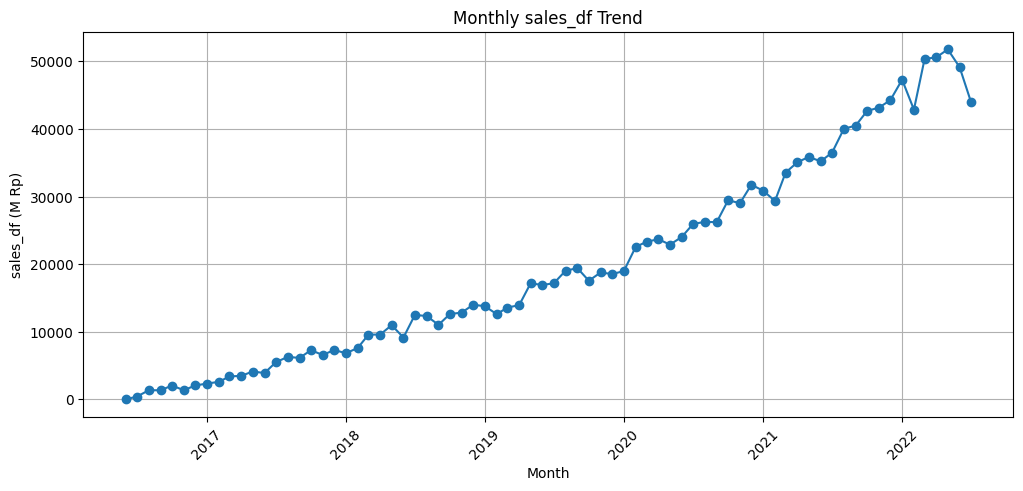

In [12]:
# Add time features
sales_df["month"] = sales_df["created_at"].dt.month
sales_df["year"] = sales_df["created_at"].dt.year
sales_df["day_of_week"] = sales_df["created_at"].dt.dayofweek
sales_df["hour"] = sales_df["created_at"].dt.hour

# Monthly sales_df
monthly = sales_df.groupby(["year", "month"])["total_amount"].sum().reset_index()
monthly["date"] = pd.to_datetime(monthly[["year", "month"]].assign(day=1))
plt.figure(figsize=(12, 5))
plt.plot(monthly["date"], monthly["total_amount"] / 1e6, marker="o")
plt.title("Monthly sales_df Trend")
plt.xlabel("Month")
plt.ylabel("sales_df (M Rp)")
plt.xticks(rotation=45)
plt.grid(True)
plt.show()

C:\Users\hayao\AppData\Local\Temp\ipykernel_19584\3436542299.py:2: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  gender_sales_df = sales_df.groupby('gender')['total_amount'].sum()


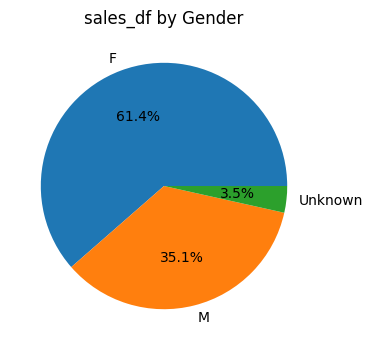

In [13]:
# Gender distribution of sales_df
gender_sales_df = sales_df.groupby("gender")["total_amount"].sum()
plt.figure(figsize=(6, 4))
gender_sales_df.plot(kind="pie", autopct="%1.1f%%")
plt.title("sales_df by Gender")
plt.ylabel("")
plt.show()

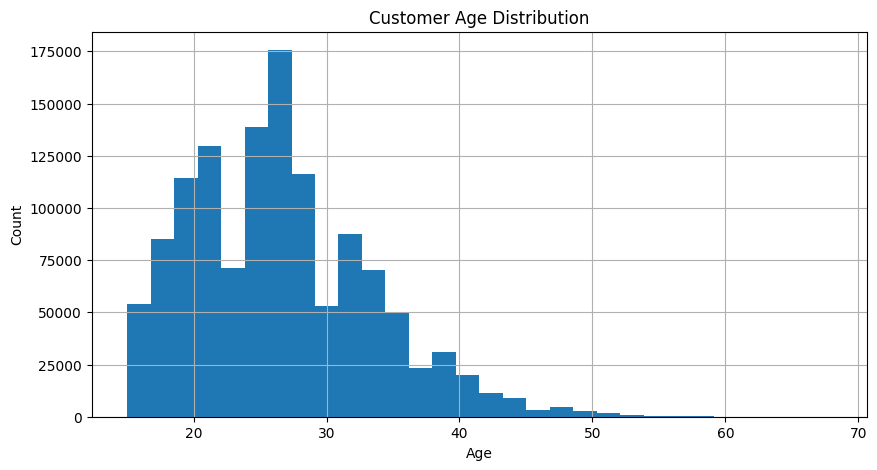

In [14]:
# Age distribution (if age exists)
if "age" in sales_df.columns:
    plt.figure(figsize=(10, 5))
    sales_df["age"].hist(bins=30)
    plt.title("Customer Age Distribution")
    plt.xlabel("Age")
    plt.ylabel("Count")
    plt.show()

## Top performing

C:\Users\hayao\AppData\Local\Temp\ipykernel_19584\674822086.py:2: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  cat_sales_df = sales_df.groupby('masterCategory')['total_amount'].sum().sort_values(ascending=False)


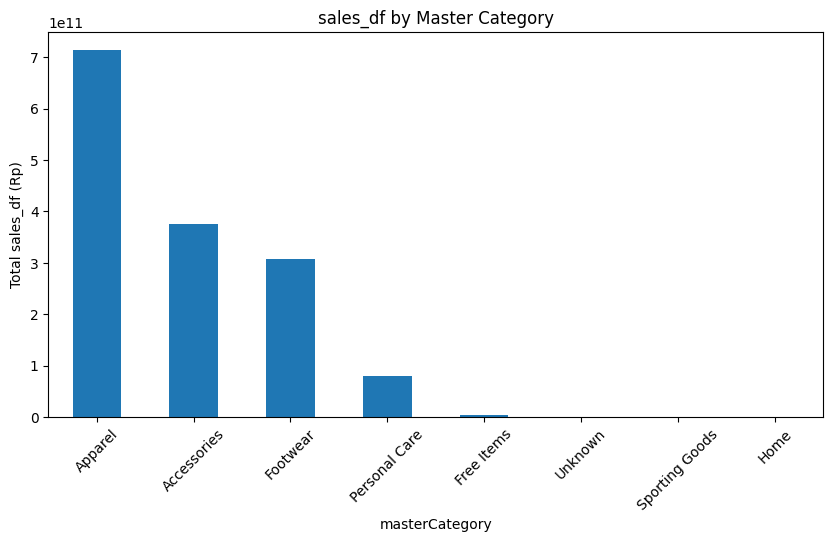

In [15]:
# Top categories by sales_df
cat_sales_df = (
    sales_df.groupby("masterCategory")["total_amount"]
    .sum()
    .sort_values(ascending=False)
)
plt.figure(figsize=(10, 5))
cat_sales_df.plot(kind="bar")
plt.title("sales_df by Master Category")
plt.ylabel("Total sales_df (Rp)")
plt.xticks(rotation=45)
plt.show()

C:\Users\hayao\AppData\Local\Temp\ipykernel_19584\1448471304.py:2: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  brand_sales_df = sales_df.groupby('brand')['total_amount'].sum().sort_values(ascending=False).head(10)


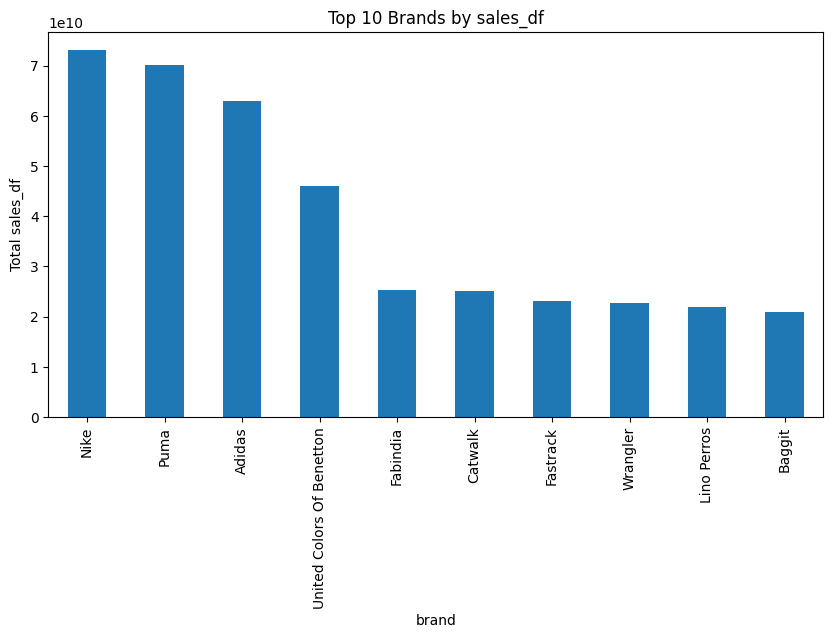

In [16]:
# Top brands
brand_sales_df = (
    sales_df.groupby("brand")["total_amount"]
    .sum()
    .sort_values(ascending=False)
    .head(10)
)
plt.figure(figsize=(10, 5))
brand_sales_df.plot(kind="bar")
plt.title("Top 10 Brands by sales_df")
plt.ylabel("Total sales_df")
plt.show()

C:\Users\hayao\AppData\Local\Temp\ipykernel_19584\2193339339.py:2: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  colour_sales_df = sales_df.groupby('baseColour')['total_amount'].sum().sort_values(ascending=False).head(10)


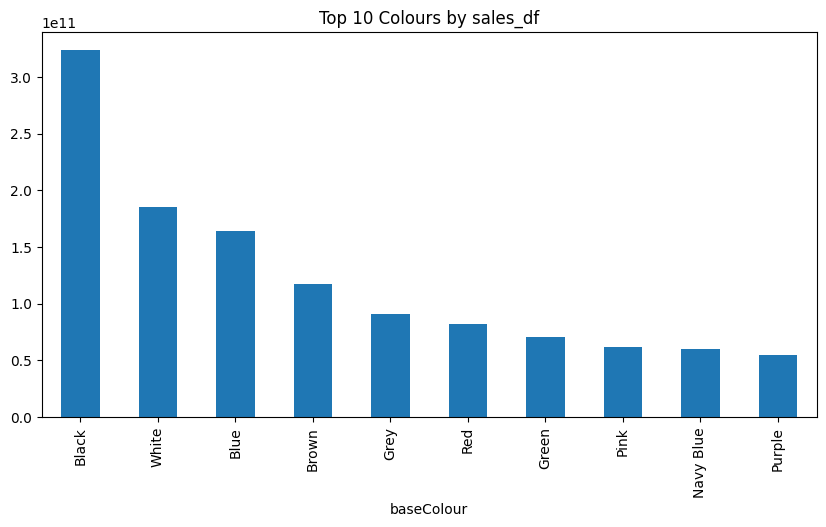

In [17]:
# Colour popularity
colour_sales_df = (
    sales_df.groupby("baseColour")["total_amount"]
    .sum()
    .sort_values(ascending=False)
    .head(10)
)
plt.figure(figsize=(10, 5))
colour_sales_df.plot(kind="bar")
plt.title("Top 10 Colours by sales_df")
plt.show()

## Multivariant analysis

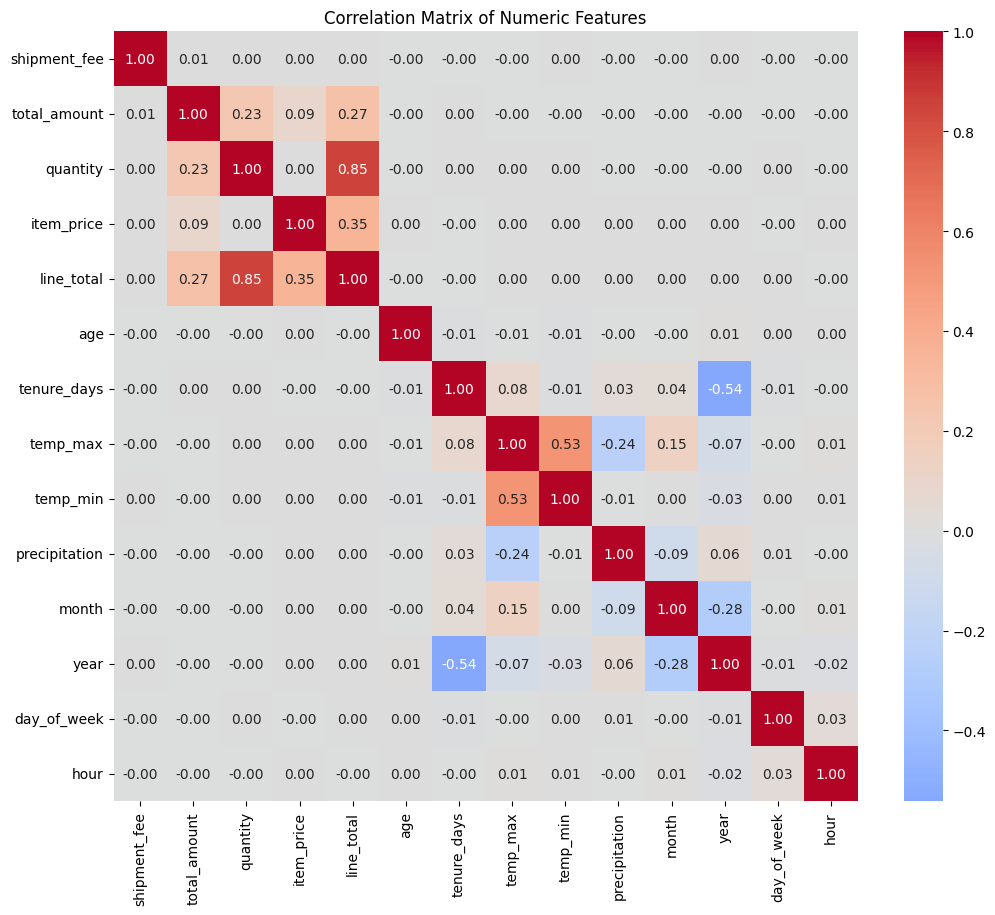

In [18]:
# Select numeric columns for correlation
num_cols = sales_df.select_dtypes(include=[np.number]).columns
# Exclude IDs if necessary
num_cols = [
    c
    for c in num_cols
    if c not in ["customer_id", "product_id", "promo_amount", "discount_pct"]
]  # adjust as needed

corr = sales_df[num_cols].corr()
plt.figure(figsize=(12, 10))
sns.heatmap(corr, annot=True, fmt=".2f", cmap="coolwarm", center=0)
plt.title("Correlation Matrix of Numeric Features")
plt.show()

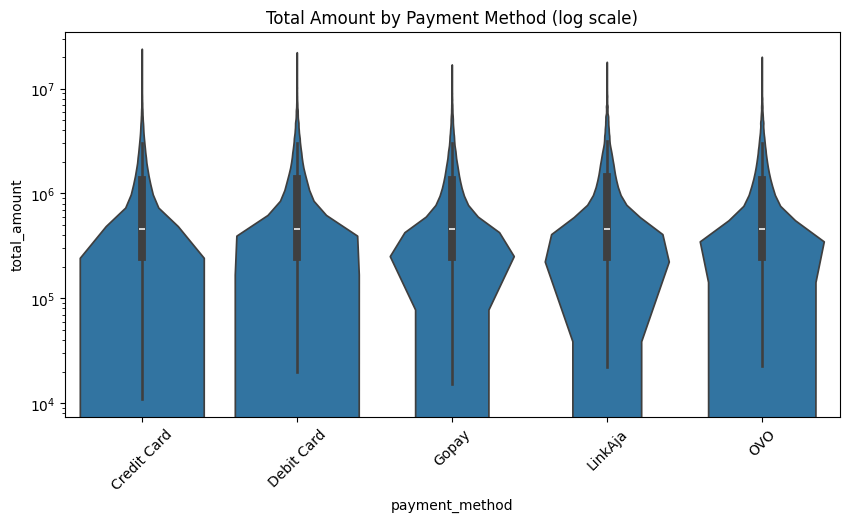

In [19]:
plt.figure(figsize=(10, 5))
sns.violinplot(
    x="payment_method", y="total_amount", data=sales_df, density_norm="width"
)
plt.yscale("log")
plt.xticks(rotation=45)
plt.title("Total Amount by Payment Method (log scale)")
plt.show()

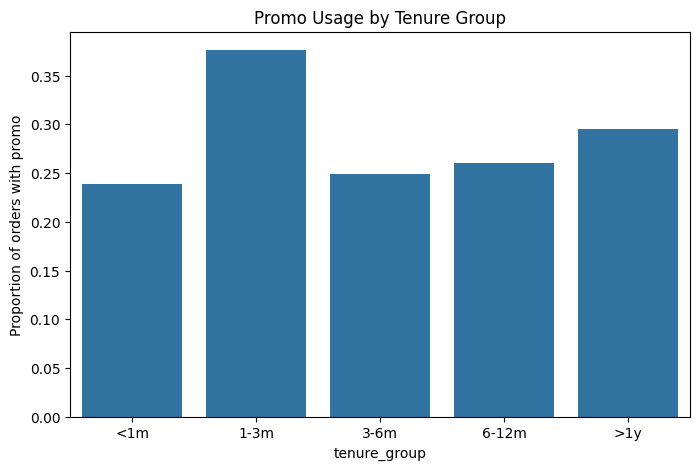

In [20]:
# Compute promo usage per customer
cust_promo = (
    sales_df.groupby("customer_id")
    .agg(
        tenure_days=("tenure_days", "first"),
        promo_ratio=("is_discounted", "mean"),
        total_spent=("total_amount", "sum"),
    )
    .dropna()
)

# Bin tenure
cust_promo["tenure_group"] = pd.cut(
    cust_promo["tenure_days"],
    bins=[0, 30, 90, 180, 365, 1000],
    labels=["<1m", "1-3m", "3-6m", "6-12m", ">1y"],
)

# Plot promo ratio by tenure group
plt.figure(figsize=(8, 5))
sns.barplot(data=cust_promo, x="tenure_group", y="promo_ratio", errorbar=None)
plt.title("Promo Usage by Tenure Group")
plt.ylabel("Proportion of orders with promo")
plt.show()

“New customers (first month) use promotions most heavily, while long‑term customers rely on them less.”

## Sales and weather

In [21]:
sales_df[sales_df["articleType"].str.contains("Rain", case=False, na=False)].nunique()

created_at             568
customer_id            544
booking_id             568
session_id             568
payment_method           5
payment_status           2
promo_amount           220
promo_code               9
shipment_fee             6
total_amount           568
is_discounted            2
discount_pct           221
product_id              20
quantity                 9
item_price             568
line_total             568
shipment_date_limit    469
masterCategory           1
subCategory              2
articleType              2
baseColour               8
product_season           2
brand                    2
gender                   3
age                     35
device_type              3
home_location           33
tenure_days            397
temp_max               254
temp_min               245
precipitation          269
holiday_name            16
month                   12
year                     7
day_of_week              7
hour                    24
dtype: int64

<Figure size 1200x800 with 0 Axes>

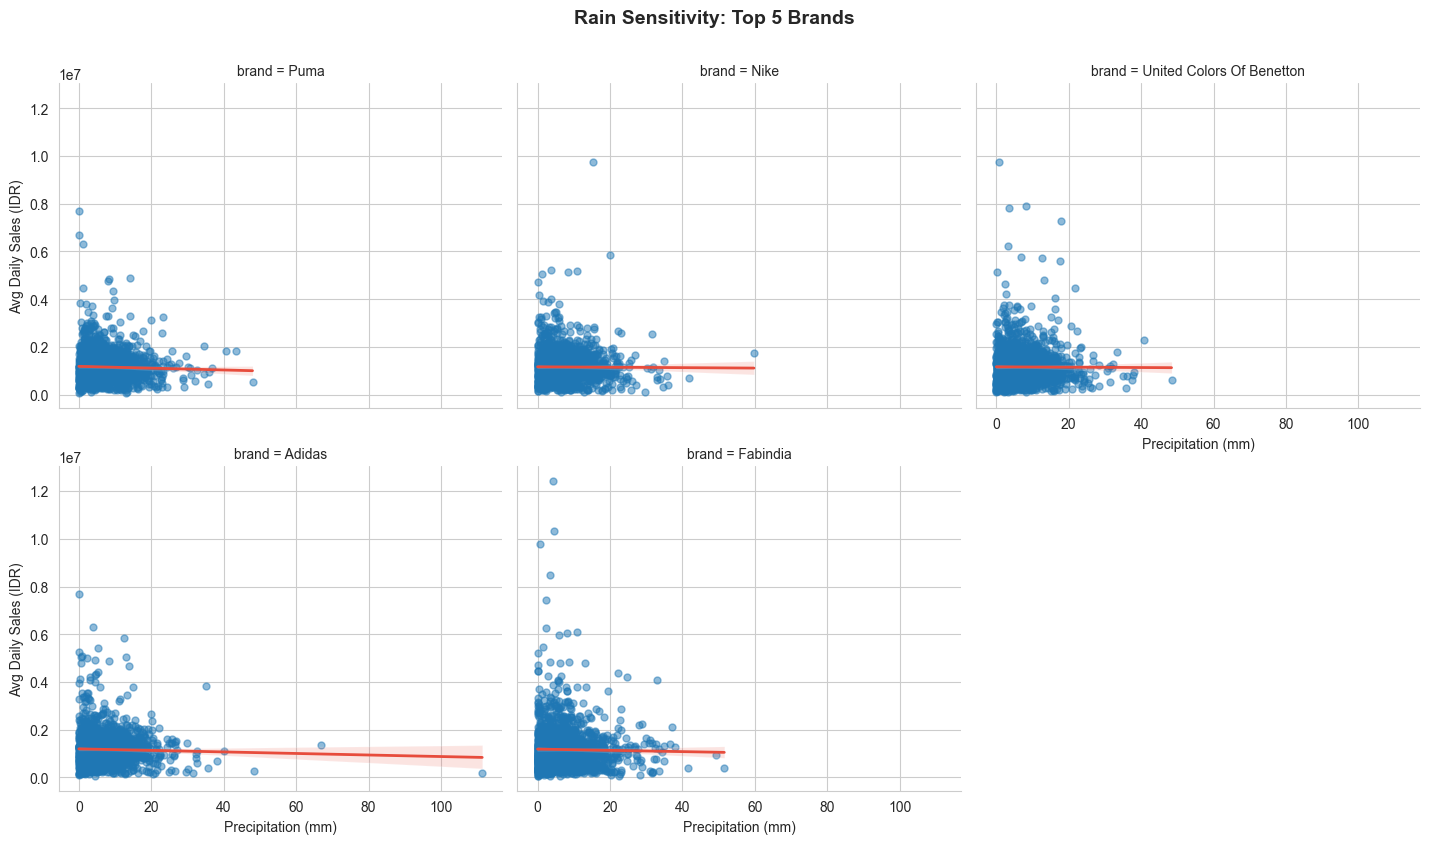

In [24]:
# 1. Fast Filtering using DuckDB
query = """
WITH TopBrands AS (
    SELECT brand
    FROM sales_df
    GROUP BY brand
    ORDER BY SUM(total_amount) DESC
    LIMIT 5
)
SELECT 
    CAST(created_at AS DATE) AS date,
    brand,
    AVG(total_amount) AS avg_daily_sales,
    AVG(precipitation) AS daily_precip
FROM sales_df
WHERE brand IN (SELECT brand FROM TopBrands)
GROUP BY CAST(created_at AS DATE), brand
"""

plot_data = duckdb.query(query).df()

# 2. THE FIX: Erase the "Ghost" Categories
# By casting it to a string just for the plot, Seaborn forgets about the other 100+ empty brands.
plot_data["brand"] = plot_data["brand"].astype(str)

# 3. Visualization
plt.figure(figsize=(12, 8))
sns.set_style("whitegrid")

g = sns.lmplot(
    data=plot_data,
    x="daily_precip",
    y="avg_daily_sales",
    col="brand",
    col_wrap=3,
    scatter_kws={"alpha": 0.5, "s": 25},
    line_kws={"color": "#e74c3c", "lw": 2},
    height=4,
    aspect=1.2,
)

g.set_axis_labels("Precipitation (mm)", "Avg Daily Sales (IDR)")
g.fig.suptitle("Rain Sensitivity: Top 5 Brands", y=1.05, fontsize=14, fontweight="bold")

plt.show()

In [25]:
# Define rainy (precipitation > 1 mm)
sales_df["rainy"] = sales_df["precipitation"] > 1

# Pivot
brand_rain = (
    sales_df.groupby(["brand", "rainy"])["total_amount"].sum().unstack(fill_value=0)
)
brand_rain.columns = ["not_rainy", "rainy"]
brand_rain["pct_change"] = (
    (brand_rain["rainy"] - brand_rain["not_rainy"]) / brand_rain["not_rainy"] * 100
)

# Top 10 brands
top_brands = sales_df.groupby("brand")["total_amount"].sum().nlargest(10).index
brand_rain.loc[top_brands].sort_values("pct_change", ascending=False)

C:\Users\hayao\AppData\Local\Temp\ipykernel_19584\789352216.py:5: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  brand_rain = sales_df.groupby(['brand', 'rainy'])['total_amount'].sum().unstack(fill_value=0)
C:\Users\hayao\AppData\Local\Temp\ipykernel_19584\789352216.py:10: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  top_brands = sales_df.groupby('brand')['total_amount'].sum().nlargest(10).index


,not_rainy,rainy,pct_change
brand,,,
Wrangler,7154901315,15499782177,116.631670
Fabindia,8005244286,17316484653,116.314256
Baggit,6584718229,14243533060,116.311960
United Colors Of Benetton,14665483917,31374435143,113.933855
Fastrack,7385958813,15721513167,112.856767
Adidas,20459799573,42554935044,107.992922
Catwalk,8185185950,16915306050,106.657566
Puma,22917104877,47190584000,105.918611
Nike,23873476809,49156241059,105.903151


C:\Users\hayao\AppData\Local\Temp\ipykernel_19584\124187270.py:9: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  rain_sales_df = rainwear.groupby('rain_category')['total_amount'].sum()


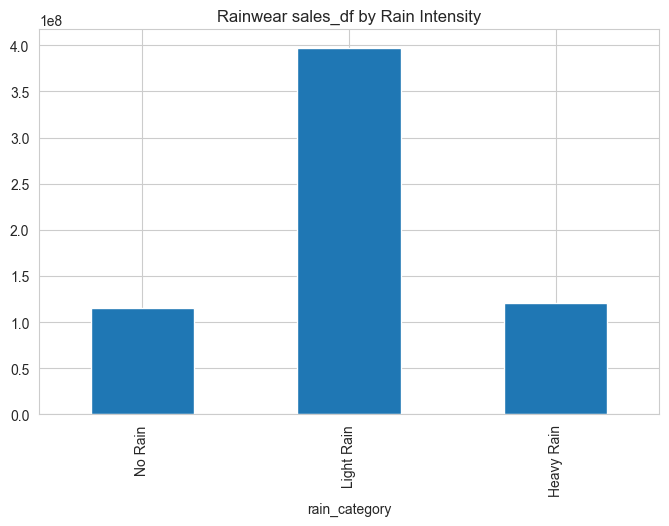

In [26]:
# Impact of rain on specific categories (e.g., Rainwear)
if "precipitation" in sales_df.columns:
    # Create rain categories
    sales_df["rain_category"] = pd.cut(
        sales_df["precipitation"],
        bins=[-1, 0.1, 10, 100],
        labels=["No Rain", "Light Rain", "Heavy Rain"],
    )

    # For rainwear category
    rainwear = sales_df[
        sales_df["articleType"].str.contains("Rain", case=False, na=False)
    ]
    if not rainwear.empty:
        rain_sales_df = rainwear.groupby("rain_category")["total_amount"].sum()
        plt.figure(figsize=(8, 5))
        rain_sales_df.plot(kind="bar")
        plt.title("Rainwear sales_df by Rain Intensity")
        plt.show()

## Customer segemnts

### RFM

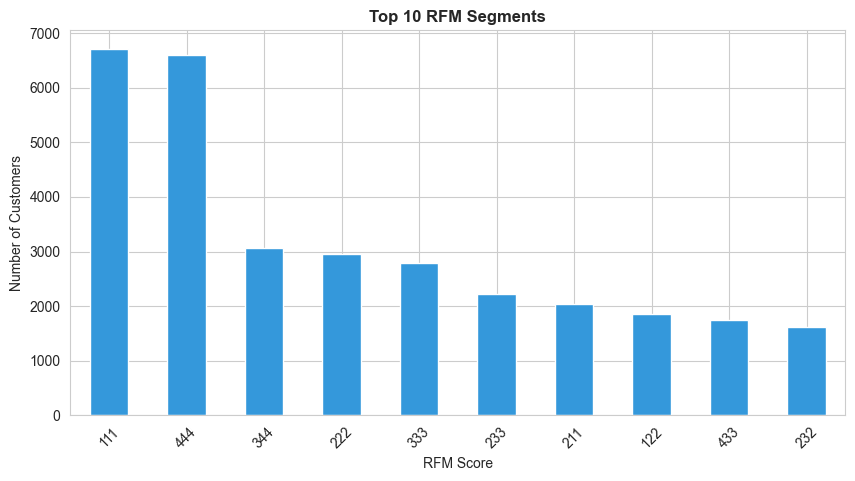

In [ ]:
# 1. Use DuckDB to do the heavy lifting instantly
query = """
WITH Aggregated AS (
    SELECT 
        customer_id,
        MAX(created_at) AS last_purchase,
        COUNT(DISTINCT booking_id) AS frequency,
        SUM(total_amount) AS monetary
    FROM sales_df
    GROUP BY customer_id
)
SELECT 
    customer_id,
    -- Calculate days between the global max date and their last purchase
    DATE_DIFF('day', CAST(last_purchase AS DATE), CAST((SELECT MAX(created_at) FROM sales_df) AS DATE)) AS recency,
    frequency,
    monetary
FROM Aggregated
"""

rfm = duckdb.query(query).df()

# 2. Assign quartiles in Pandas (Instant on the small aggregated table)
rfm["R"] = pd.qcut(rfm["recency"], 4, labels=["4", "3", "2", "1"])
rfm["F"] = pd.qcut(
    rfm["frequency"].rank(method="first"), 4, labels=["1", "2", "3", "4"]
)
rfm["M"] = pd.qcut(rfm["monetary"], 4, labels=["1", "2", "3", "4"])
rfm["RFM_Score"] = rfm["R"].astype(str) + rfm["F"].astype(str) + rfm["M"].astype(str)

# 3. Plot Top 10 Segments
plt.figure(figsize=(10, 5))
rfm["RFM_Score"].value_counts().head(10).plot(kind="bar", color="#3498db")
plt.title("Top 10 RFM Segments", fontweight="bold")
plt.xlabel("RFM Score")
plt.ylabel("Number of Customers")
plt.xticks(rotation=45)
plt.show()

### Holidays customers behavior

In [32]:
# 1. Get the list of unique holiday dates from your existing data
holiday_dates = sales_df[sales_df["is_holiday"] == 1]["created_at"].dt.date.unique()

# 2. Create a function or list of dates representing the "Lead-up Window"
# We define the window as 14 days BEFORE the holiday
shopping_window_dates = []
for h_date in holiday_dates:
    # Create a range of 14 days ending the day BEFORE the holiday
    window = pd.date_range(end=h_date - pd.Timedelta(days=1), periods=30)
    shopping_window_dates.extend(window.date)

# 3. Add the 'is_shopping_window' flag to your sales_df table
sales_df["is_shopping_window"] = sales_df["created_at"].dt.date.isin(
    set(shopping_window_dates)
)

# 4. Compare the groups
window_analysis = sales_df.groupby("is_shopping_window").agg(
    daily_avg_revenue=("total_amount", "mean"),
    avg_items_per_order=("quantity", "mean"),
    total_transactions=("booking_id", "nunique"),
)

print(window_analysis)

                    daily_avg_revenue  avg_items_per_order  total_transactions
is_shopping_window                                                            
False                    1.187462e+06             1.479178              223798
True                     1.179474e+06             1.473685              628786


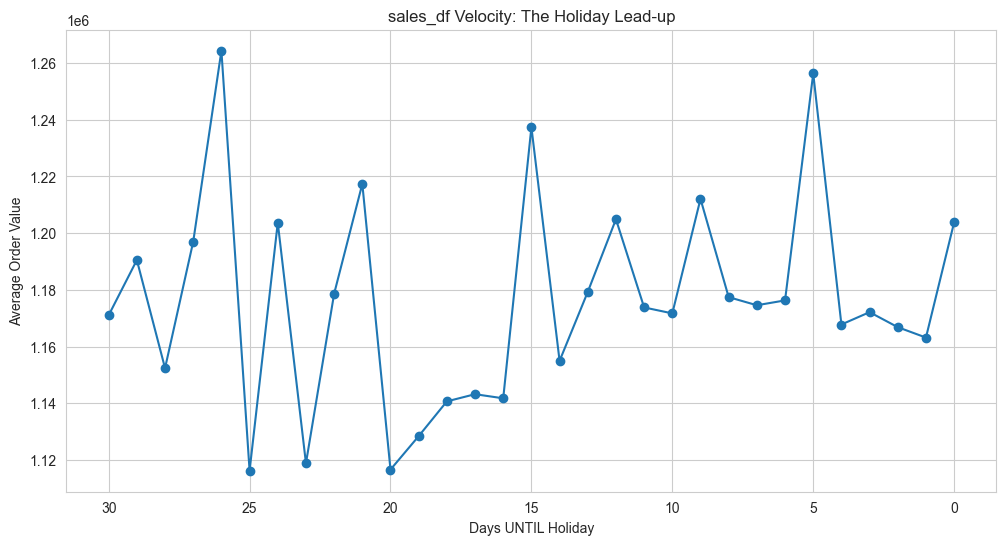

In [33]:
# Calculate days until the nearest holiday for each transaction
def days_to_holiday(row_date, h_dates):
    # Find the next holiday after this date
    future_holidays = [h for h in h_dates if h >= row_date]
    if not future_holidays:
        return np.nan
    return (min(future_holidays) - row_date).days


holiday_dates = sales_df[sales_df["is_holiday"] == 1]["created_at"].dt.date.unique()
# Apply to a sample or the whole set (Note: this can be slow on 1.2M rows, use a sample first)
h_dates_set = set(holiday_dates)
sales_df["days_until_holiday"] = sales_df["created_at"].dt.date.apply(
    lambda x: days_to_holiday(x, holiday_dates)
)

# Plot the sales_df trend leading up to the holiday
plt.figure(figsize=(12, 6))
# Focus on the 30 days before the holiday
trend = (
    sales_df[sales_df["days_until_holiday"] <= 30]
    .groupby("days_until_holiday")["total_amount"]
    .mean()
)
trend.sort_index(ascending=False).plot(kind="line", marker="o")

plt.title("sales_df Velocity: The Holiday Lead-up")
plt.xlabel("Days UNTIL Holiday")
plt.ylabel("Average Order Value")
plt.gca().invert_xaxis()  # So the holiday is on the right
plt.grid(True)
plt.show()

“Sales increase sharply in the 5 days before a holiday, peaking 2 days prior.”

In [34]:
# 1. Identify the "First Purchase Date" for every customer
# (We use the sales_df table as the source of truth)
first_purchase = sales_df.groupby("customer_id")["created_at"].min().reset_index()
first_purchase.columns = ["customer_id", "first_purchase_at"]
first_purchase["first_purchase_date"] = first_purchase["first_purchase_at"].dt.date

# 2. Get a list of dates that are in the Shopping Window
window_dates = sales_df[sales_df["is_shopping_window"] == True][
    "created_at"
].dt.date.unique()

# 3. Mark which customers were "Acquired" during a Window
first_purchase["is_acquired_in_window"] = first_purchase["first_purchase_date"].isin(
    window_dates
)

# 4. Compare Daily Acquisition Rate
# We count how many unique customers made their FIRST purchase in vs out of the window
acquisition_summary = (
    first_purchase.groupby("is_acquired_in_window")
    .size()
    .reset_index(name="new_customers_count")
)

# To be fair, normalize by the number of days in each category
num_days_window = len(window_dates)
num_days_total = sales_df["created_at"].dt.date.nunique()
num_days_normal = num_days_total - num_days_window

acquisition_summary["new_customers_per_day"] = acquisition_summary.apply(
    lambda x: (
        x["new_customers_count"] / num_days_window
        if x["is_acquired_in_window"]
        else x["new_customers_count"] / num_days_normal
    ),
    axis=1,
)

print(acquisition_summary)

   is_acquired_in_window  new_customers_count  new_customers_per_day
0                  False                18880               20.63388
1                   True                31825               24.33104


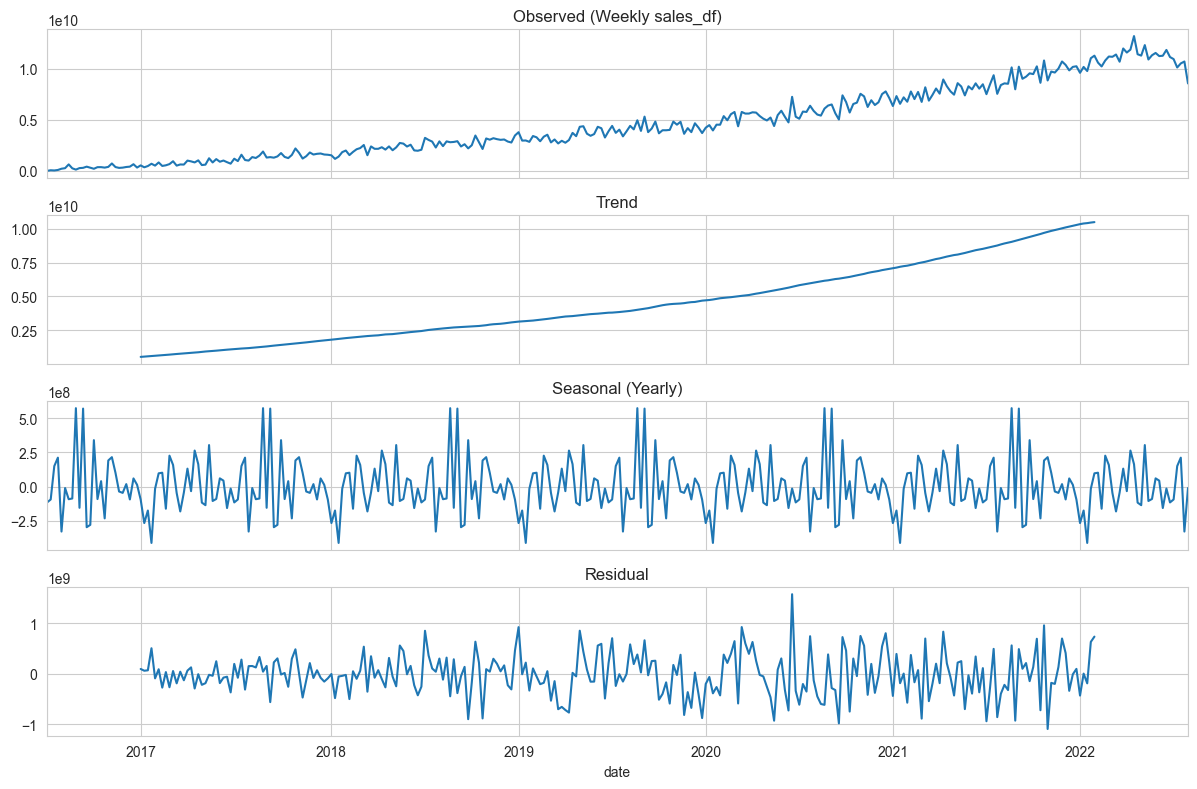

In [35]:
# Aggregate to weekly sales_df to reduce noise
daily_sales_df = (
    sales_df.groupby(sales_df["created_at"].dt.date)["total_amount"].sum().reset_index()
)
daily_sales_df.columns = ["date", "total_amount"]
daily_sales_df["date"] = pd.to_datetime(daily_sales_df["date"])
daily_sales_df = daily_sales_df.set_index("date").asfreq("D").fillna(0)

# Resample to weekly (sum)
weekly_sales_df = daily_sales_df.resample("W").sum()

# Decompose with yearly period (52 weeks)
result = seasonal_decompose(
    weekly_sales_df["total_amount"], model="additive", period=52
)

# Plot with cleaner axes
fig, axes = plt.subplots(4, 1, figsize=(12, 8), sharex=True)
result.observed.plot(ax=axes[0], title="Observed (Weekly sales_df)")
result.trend.plot(ax=axes[1], title="Trend")
result.seasonal.plot(ax=axes[2], title="Seasonal (Yearly)")
result.resid.plot(ax=axes[3], title="Residual")
plt.tight_layout()
plt.show()

C:\Users\hayao\AppData\Local\Temp\ipykernel_19584\103743998.py:4: UserWarning: Converting to PeriodArray/Index representation will drop timezone information.
  first_purchase['cohort'] = first_purchase['first_purchase'].dt.to_period('M')
C:\Users\hayao\AppData\Local\Temp\ipykernel_19584\103743998.py:8: UserWarning: Converting to PeriodArray/Index representation will drop timezone information.
  sales_df_with_cohort['order_month'] = sales_df_with_cohort['created_at'].dt.to_period('M')


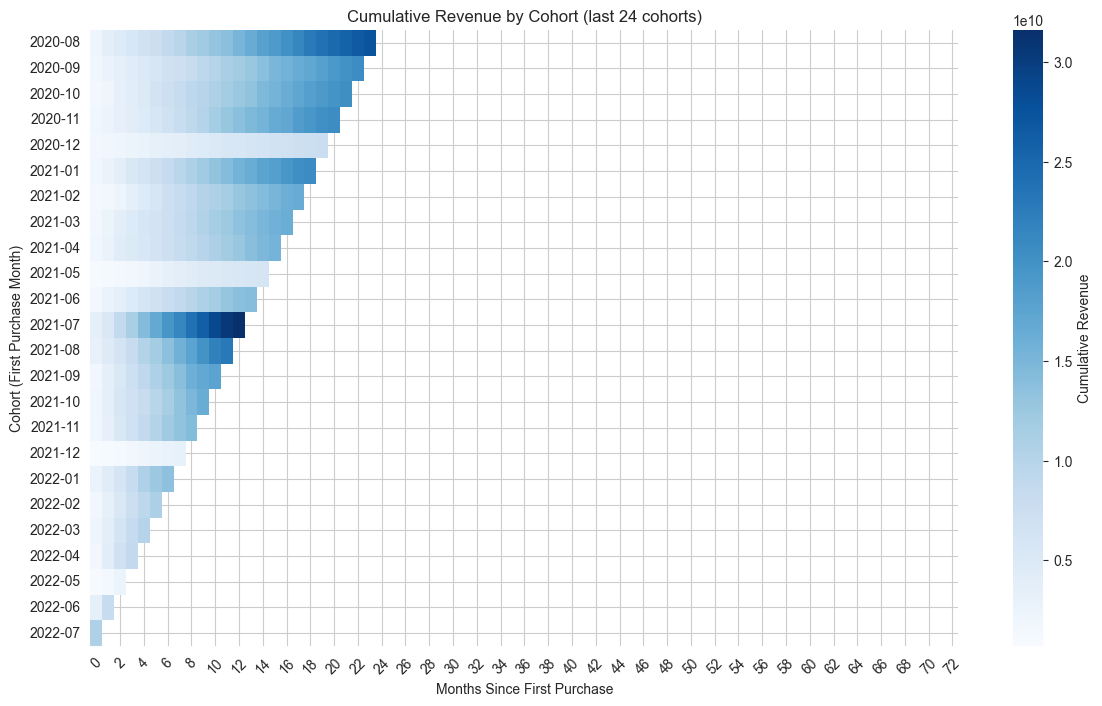

In [44]:
# First purchase date per customer
first_purchase = sales_df.groupby("customer_id")["created_at"].min().reset_index()
first_purchase.columns = ["customer_id", "first_purchase"]
first_purchase["cohort"] = first_purchase["first_purchase"].dt.to_period("M")

# Merge and compute months since first purchase
sales_df_with_cohort = sales_df.merge(first_purchase, on="customer_id")
sales_df_with_cohort["order_month"] = sales_df_with_cohort["created_at"].dt.to_period(
    "M"
)
sales_df_with_cohort["months_since"] = sales_df_with_cohort["order_month"].astype(
    "int64"
) - sales_df_with_cohort["cohort"].astype("int64")

# Aggregate cumulative revenue per cohort and months_since
cohort_data = (
    sales_df_with_cohort.groupby(["cohort", "months_since"])["total_amount"]
    .sum()
    .reset_index()
)
cohort_data["cumulative_revenue"] = cohort_data.groupby("cohort")[
    "total_amount"
].cumsum()

# Pivot and restrict to last 12 cohorts for readability
cohort_pivot = cohort_data.pivot(
    index="cohort", columns="months_since", values="cumulative_revenue"
)
cohort_pivot = cohort_pivot.sort_index().tail(
    24
)  # show only the most recent 24 cohorts

# Plot heatmap
plt.figure(figsize=(14, 8))
sns.heatmap(
    cohort_pivot, fmt=".0f", cmap="Blues", cbar_kws={"label": "Cumulative Revenue"}
)
plt.title("Cumulative Revenue by Cohort (last 24 cohorts)")
plt.xlabel("Months Since First Purchase")
plt.ylabel("Cohort (First Purchase Month)")
plt.xticks(rotation=45)
plt.show()

Inter‑purchase time statistics (days):
count    1.203880e+06
mean     2.849227e+01
std      6.285244e+01
min      0.000000e+00
25%      0.000000e+00
50%      1.100000e+01
75%      2.900000e+01
max      1.109000e+03
Name: inter_purchase_days, dtype: float64


C:\Users\hayao\AppData\Roaming\Python\Python310\site-packages\IPython\core\pylabtools.py:170: UserWarning: Glyph 8209 (\N{NON-BREAKING HYPHEN}) missing from font(s) Arial.
  fig.canvas.print_figure(bytes_io, **kw)


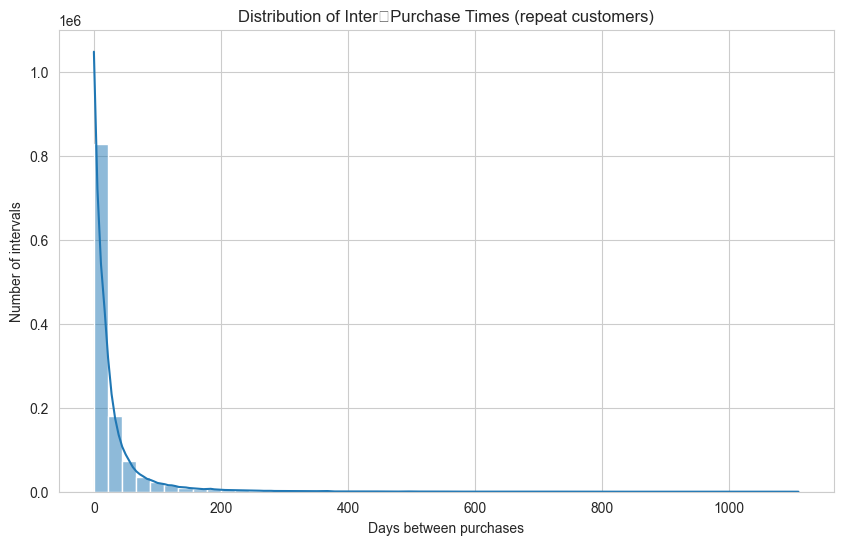

In [45]:
# Get all purchases per customer sorted by date
purchases = sales_df[["customer_id", "created_at"]].sort_values(
    ["customer_id", "created_at"]
)

# Compute inter‑purchase days for customers with at least 2 purchases
repeat_customers = purchases.groupby("customer_id").filter(lambda x: len(x) >= 2)
repeat_customers["prev_date"] = repeat_customers.groupby("customer_id")[
    "created_at"
].shift(1)
repeat_customers["inter_purchase_days"] = (
    repeat_customers["created_at"] - repeat_customers["prev_date"]
).dt.days
repeat_customers = repeat_customers.dropna(subset=["inter_purchase_days"])

# Basic statistics
print("Inter‑purchase time statistics (days):")
print(repeat_customers["inter_purchase_days"].describe())

# Histogram with KDE
plt.figure(figsize=(10, 6))
sns.histplot(
    repeat_customers["inter_purchase_days"], bins=50, kde=True, log_scale=(False, False)
)
plt.title("Distribution of Inter‑Purchase Times (repeat customers)")
plt.xlabel("Days between purchases")
plt.ylabel("Number of intervals")
plt.grid(True)
plt.show()

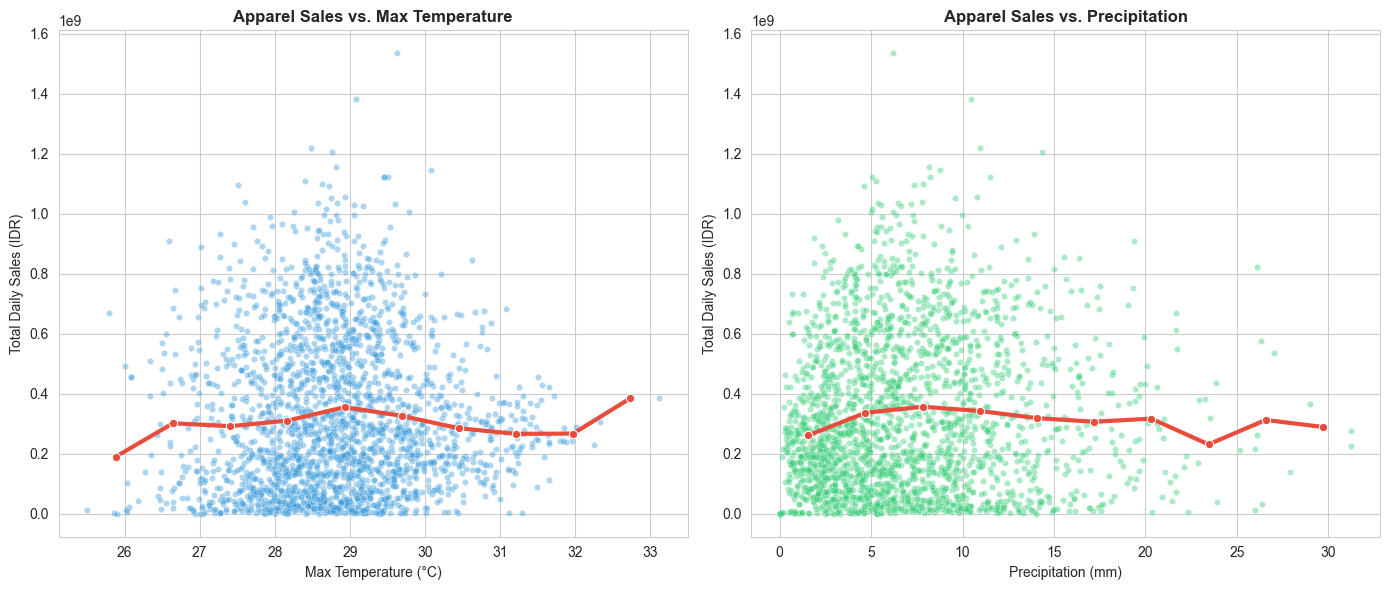

In [46]:
# 1. Filter for Apparel and extract the date (fast normalization)
apparel = sales_df[sales_df["masterCategory"] == "Apparel"].copy()
apparel["sale_day"] = apparel["created_at"].dt.normalize()

# 2. Daily aggregated data directly from the Gold table
# We sum the sales, and take the mean of the weather for that day
daily_apparel = (
    apparel.groupby("sale_day")
    .agg({"total_amount": "sum", "temp_max": "mean", "precipitation": "mean"})
    .reset_index()
)

# 3. Bin temperature into ranges and compute average sales per bin
temp_bins = pd.cut(daily_apparel["temp_max"], bins=10)
temp_means = (
    daily_apparel.groupby(temp_bins, observed=False)["total_amount"]
    .mean()
    .reset_index()
)
# Extract the midpoint of the bin for plotting
temp_means["temp_mid"] = temp_means["temp_max"].apply(lambda x: x.mid).astype(float)

# 4. Bin precipitation into ranges
precip_bins = pd.cut(daily_apparel["precipitation"], bins=10)
precip_means = (
    daily_apparel.groupby(precip_bins, observed=False)["total_amount"]
    .mean()
    .reset_index()
)
# Extract the midpoint of the bin for plotting
precip_means["precip_mid"] = (
    precip_means["precipitation"].apply(lambda x: x.mid).astype(float)
)

# 5. Visualization Setup
plt.figure(figsize=(14, 6))
sns.set_style("whitegrid")

# --- Left Plot: Max Temperature ---
plt.subplot(1, 2, 1)
sns.scatterplot(
    data=daily_apparel, x="temp_max", y="total_amount", alpha=0.4, s=20, color="#3498db"
)
sns.lineplot(
    data=temp_means,
    x="temp_mid",
    y="total_amount",
    color="#e74c3c",
    linewidth=3,
    marker="o",
)
plt.title("Apparel Sales vs. Max Temperature", fontweight="bold")
plt.xlabel("Max Temperature (°C)")
plt.ylabel("Total Daily Sales (IDR)")

# --- Right Plot: Precipitation ---
plt.subplot(1, 2, 2)
sns.scatterplot(
    data=daily_apparel,
    x="precipitation",
    y="total_amount",
    alpha=0.4,
    s=20,
    color="#2ecc71",
)
sns.lineplot(
    data=precip_means,
    x="precip_mid",
    y="total_amount",
    color="#e74c3c",
    linewidth=3,
    marker="o",
)
plt.title("Apparel Sales vs. Precipitation", fontweight="bold")
plt.xlabel("Precipitation (mm)")
plt.ylabel("Total Daily Sales (IDR)")

plt.tight_layout()
plt.show()

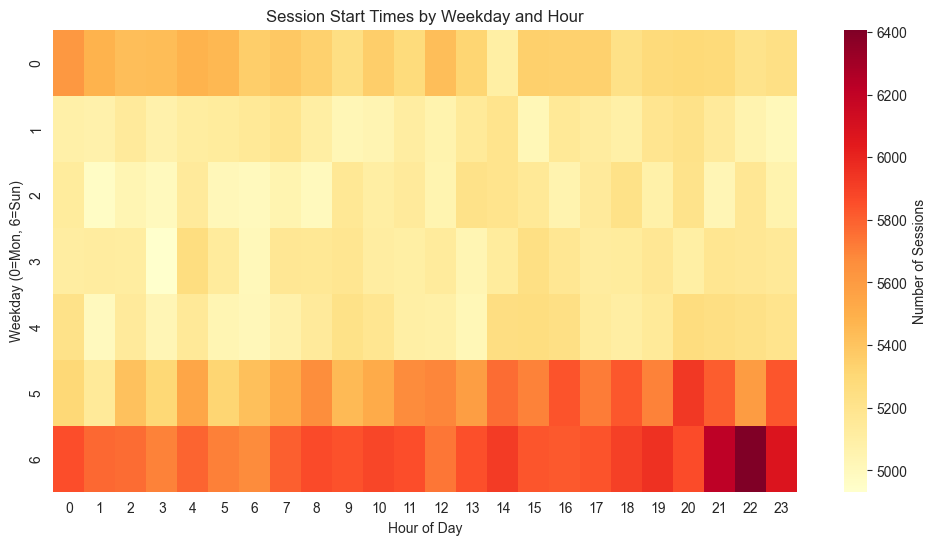

In [47]:
# Extract hour and weekday from behavior_df events
behavior_df["hour"] = behavior_df["event_time"].dt.hour
behavior_df["weekday"] = behavior_df["event_time"].dt.dayofweek  # 0=Monday, 6=Sunday

# Define event order and get first event per session
first_events = (
    behavior_df.sort_values("event_time").groupby("session_id").first().reset_index()
)
first_events["weekday"] = first_events["event_time"].dt.dayofweek
first_events["hour"] = first_events["event_time"].dt.hour

# Count sessions per hour and weekday
session_counts = (
    first_events.groupby(["weekday", "hour"]).size().reset_index(name="sessions")
)

# Pivot for heatmap
pivot = session_counts.pivot(index="weekday", columns="hour", values="sessions")

plt.figure(figsize=(12, 6))
sns.heatmap(pivot, cmap="YlOrRd", annot=False, cbar_kws={"label": "Number of Sessions"})
plt.title("Session Start Times by Weekday and Hour")
plt.xlabel("Hour of Day")
plt.ylabel("Weekday (0=Mon, 6=Sun)")
plt.show()

# Behavior table

In [48]:
behavior_df.head()

,session_id,event_name,event_time,event_id,traffic_source,product_id,quantity,item_price,payment_status,search_keywords,promo_code,promo_amount,event_hour,event_dayofweek,session_duration_sec,customer_id,gender,age,tenure_days,brand,masterCategory,subCategory,articleType,temp_max,temp_min,precipitation,holiday_name,hour,weekday
0,9d94c0e0-1b57-426d-ad59-42e6c14ccb60,ADD_TO_CART,2020-09-18 09:46:03.781168+00:00,936a4960-8d29-4f6a-ba2f-b95e108bdb98,MOBILE,13166,1,264342,Unknown,None,NO_PROMO,0,9,4,1.442611e+06,32804,F,32,1338,Skechers,Footwear,Shoes,Sports Shoes,32.400002,20.4000,0.000000,Regular Day,9,4
1,4f0c95ac-5d48-4bca-abb0-7be6d8978447,ADD_TO_CART,2016-10-04 13:43:42.133499+00:00,af7cfc1c-f215-4a98-8750-59fd62d4cabd,MOBILE,12255,1,277483,Unknown,None,NO_PROMO,0,13,1,9.433229e+02,21214,M,31,2129,Genesis,Apparel,Topwear,Shirts,28.919500,23.3195,4.599999,Regular Day,13,1
2,4f0c95ac-5d48-4bca-abb0-7be6d8978447,ADD_TO_CART,2016-10-04 13:46:54.133499+00:00,b9d898f9-27f0-4367-80d5-bcef4047ab94,MOBILE,14327,1,365797,Unknown,None,NO_PROMO,0,13,1,9.433229e+02,21214,M,31,2129,Nike,Footwear,Shoes,Casual Shoes,28.919500,23.3195,4.599999,Regular Day,13,1
3,71c50cdb-b960-45e4-a0c5-25adbef9e123,ADD_TO_CART,2018-10-29 06:30:43.456424+00:00,1895b59d-5128-49e9-8dc8-a9bba7537ec9,MOBILE,19901,2,221796,Unknown,None,NO_PROMO,0,6,0,2.840590e+07,21214,M,31,2129,Lotto,Footwear,Shoes,Flats,32.650002,23.3500,1.500000,Regular Day,6,0
4,71c50cdb-b960-45e4-a0c5-25adbef9e123,ADD_TO_CART,2018-11-17 14:23:10.456424+00:00,03e43b9b-d5c0-46b2-8627-ec203eb906ce,MOBILE,37927,6,132903,Unknown,None,NO_PROMO,0,14,5,2.840590e+07,21214,M,31,2129,Mineral,Apparel,Topwear,Tunics,34.599998,23.3500,2.400000,Regular Day,14,5


## General

In [49]:
behavior_df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 12833602 entries, 0 to 12833601
Data columns (total 29 columns):
 #   Column                Dtype              
---  ------                -----              
 0   session_id            object             
 1   event_name            category           
 2   event_time            datetime64[us, UTC]
 3   event_id              object             
 4   traffic_source        category           
 5   product_id            int32              
 6   quantity              int16              
 7   item_price            int32              
 8   payment_status        category           
 9   search_keywords       category           
 10  promo_code            category           
 11  promo_amount          int32              
 12  event_hour            uint8              
 13  event_dayofweek       uint8              
 14  session_duration_sec  float32            
 15  customer_id           int32              
 16  gender                category    

In [ ]:
behavior_df.shape

(12833602, 28)

## Univariant analysis

C:\Users\hayao\AppData\Local\Temp\ipykernel_19584\2225946992.py:3: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=event_counts.index, y=event_counts.values, palette='viridis')


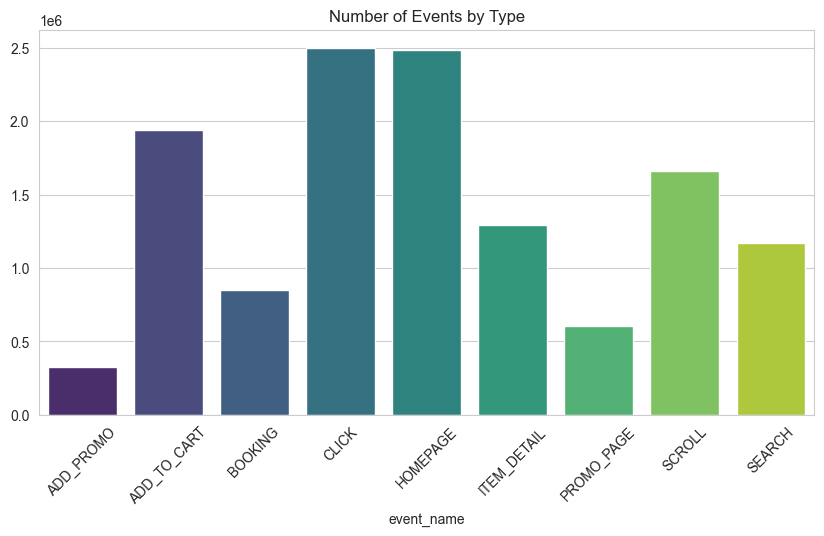

In [51]:
event_counts = behavior_df["event_name"].value_counts()
plt.figure(figsize=(10, 5))
sns.barplot(x=event_counts.index, y=event_counts.values, palette="viridis")
plt.title("Number of Events by Type")
plt.xticks(rotation=45)
plt.show()

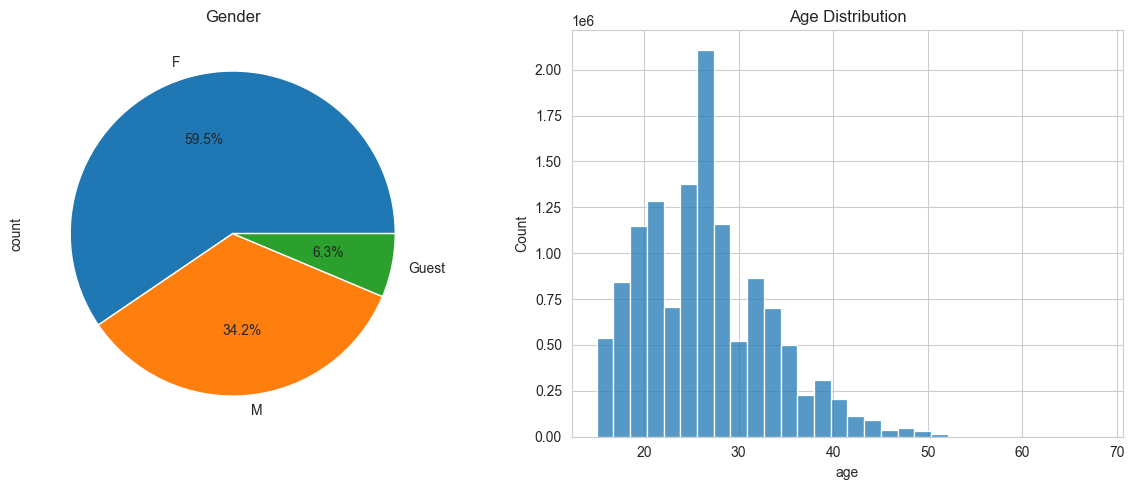

In [53]:
fig, axes = plt.subplots(1, 2, figsize=(12, 5))
behavior_df["gender"].value_counts().plot(kind="pie", autopct="%1.1f%%", ax=axes[0])
axes[0].set_title("Gender")
sns.histplot(behavior_df["age"].dropna(), bins=30, ax=axes[1])
axes[1].set_title("Age Distribution")
plt.tight_layout()
plt.show()

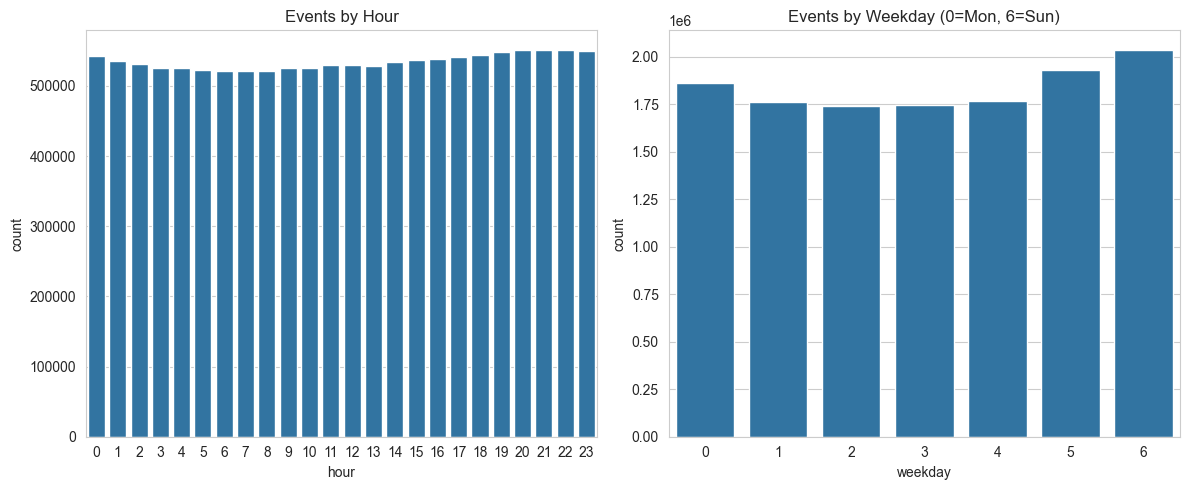

In [54]:
fig, axes = plt.subplots(1, 2, figsize=(12, 5))
sns.countplot(data=behavior_df, x="hour", ax=axes[0])
axes[0].set_title("Events by Hour")
sns.countplot(data=behavior_df, x="weekday", ax=axes[1])
axes[1].set_title("Events by Weekday (0=Mon, 6=Sun)")
plt.tight_layout()
plt.show()

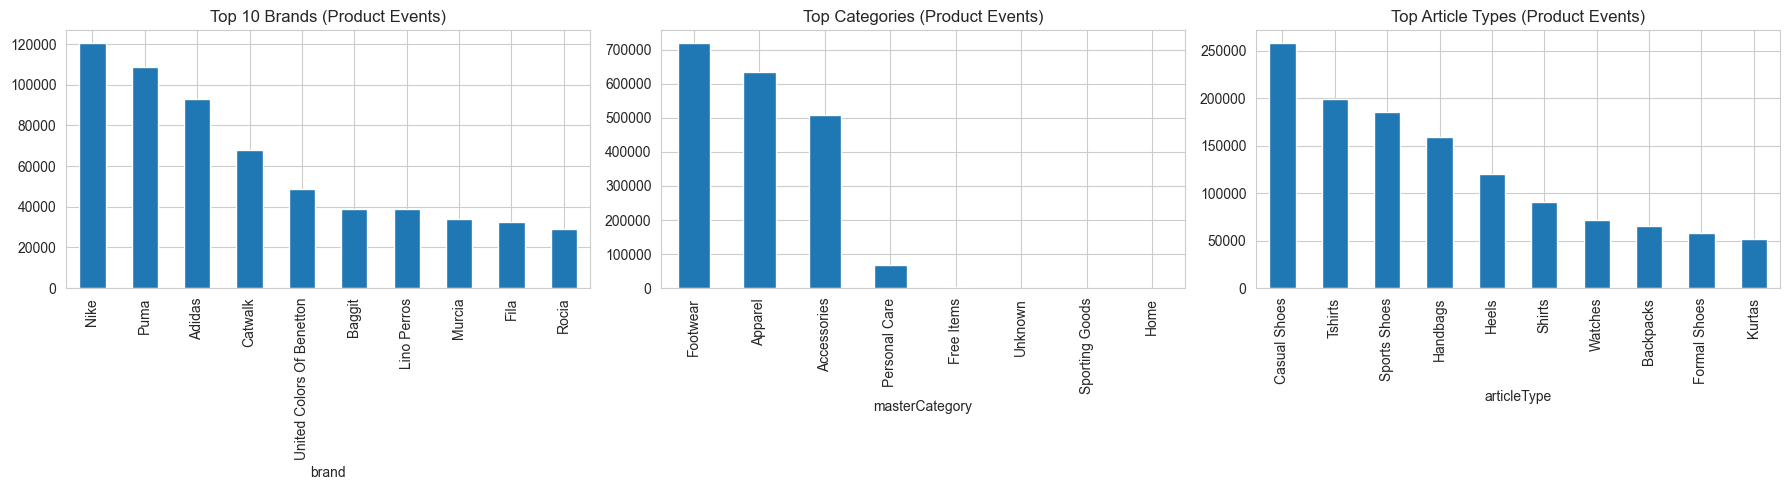

In [61]:
# For these, we consider only product‑related events (where product_id != -1)
product_events = behavior_df[behavior_df["has_product"] == 1]

fig, axes = plt.subplots(1, 3, figsize=(18, 5))
product_events["brand"].value_counts().head(10).plot(kind="bar", ax=axes[0])
axes[0].set_title("Top 10 Brands (Product Events)")
product_events["masterCategory"].value_counts().head(10).plot(kind="bar", ax=axes[1])
axes[1].set_title("Top Categories (Product Events)")
product_events["articleType"].value_counts().head(10).plot(kind="bar", ax=axes[2])
axes[2].set_title("Top Article Types (Product Events)")
plt.tight_layout()
plt.show()

## Multivariant analysis

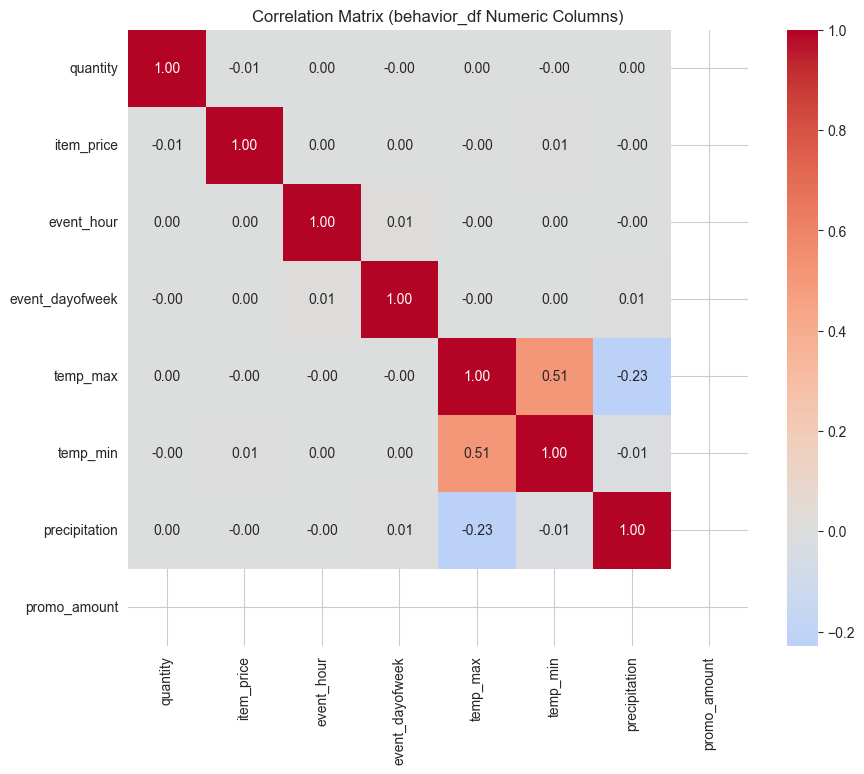

In [62]:
num_cols = [
    "quantity",
    "item_price",
    "event_hour",
    "event_dayofweek",
    "temp_max",
    "temp_min",
    "precipitation",
    "promo_amount",
]
# Subset to rows where product events have numeric data
corr_data = behavior_df[behavior_df["has_product"] == 1][num_cols].dropna()
corr = corr_data.corr()
plt.figure(figsize=(10, 8))
sns.heatmap(corr, annot=True, fmt=".2f", cmap="coolwarm", center=0)
plt.title("Correlation Matrix (behavior_df Numeric Columns)")
plt.show()

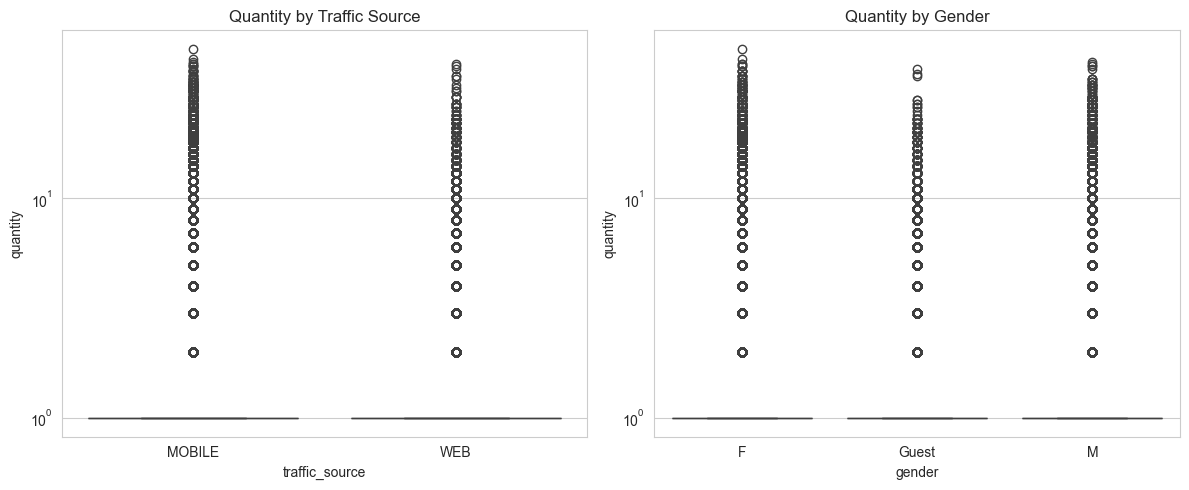

In [65]:
fig, axes = plt.subplots(1, 2, figsize=(12, 5))

sns.boxplot(
    data=behavior_df[behavior_df["has_product"] == 1],
    x="traffic_source",
    y="quantity",
    ax=axes[0],
    log_scale=True,
)
axes[0].set_title("Quantity by Traffic Source")

# Changed 'device_type' to 'gender' (or use 'masterCategory')
sns.boxplot(
    data=behavior_df[behavior_df["has_product"] == 1],
    x="gender",
    y="quantity",
    ax=axes[1],
    log_scale=True,
)
axes[1].set_title("Quantity by Gender")

plt.tight_layout()
plt.show()

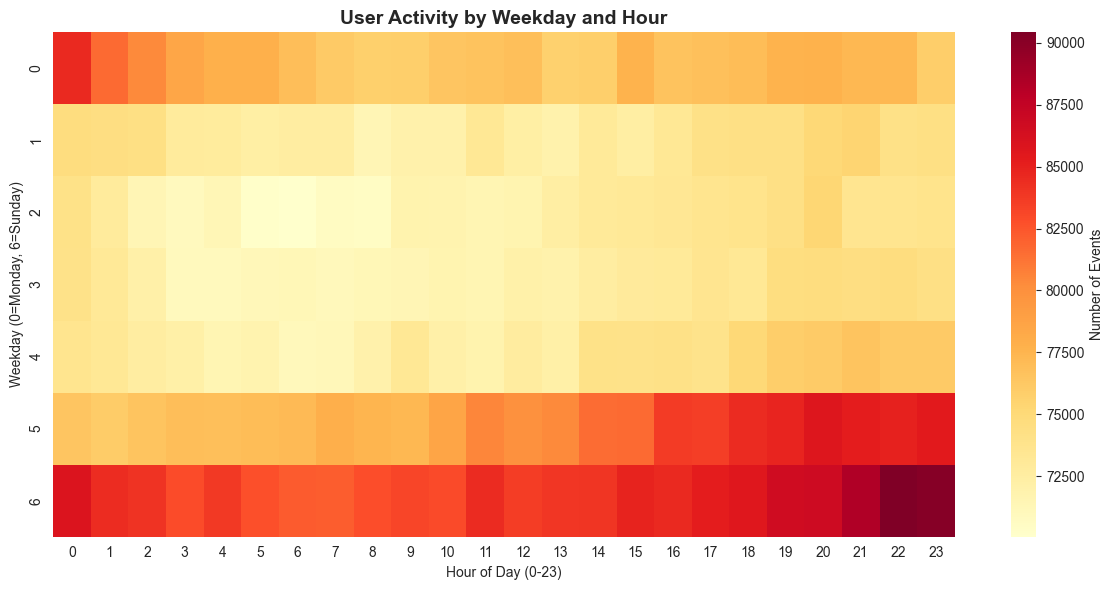

In [67]:
heatmap_data = (
    behavior_df.groupby(["event_dayofweek", "event_hour"]).size().unstack(fill_value=0)
)

plt.figure(figsize=(12, 6))
sns.heatmap(heatmap_data, cmap="YlOrRd", cbar_kws={"label": "Number of Events"})

plt.title("User Activity by Weekday and Hour", fontweight="bold", fontsize=14)
plt.xlabel("Hour of Day (0-23)")
plt.ylabel("Weekday (0=Monday, 6=Sunday)")
plt.tight_layout()

plt.show()

## Time series analysis

C:\Users\hayao\AppData\Local\Temp\ipykernel_19584\2229379618.py:1: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  daily_events = behavior_df.groupby('event_date').size().reset_index(name='count')


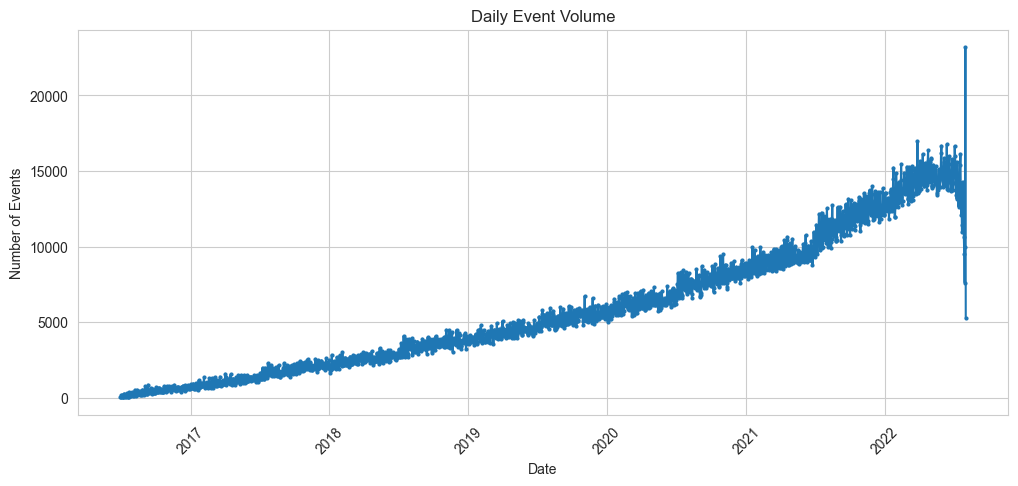

In [70]:
daily_events = behavior_df.groupby("event_date").size().reset_index(name="count")
daily_events["event_date"] = pd.to_datetime(daily_events["event_date"])
plt.figure(figsize=(12, 5))
plt.plot(daily_events["event_date"], daily_events["count"], marker="o", markersize=2)
plt.title("Daily Event Volume")
plt.xlabel("Date")
plt.ylabel("Number of Events")
plt.xticks(rotation=45)
plt.grid(True)
plt.show()

C:\Users\hayao\AppData\Local\Temp\ipykernel_19584\1309920514.py:1: UserWarning: Converting to PeriodArray/Index representation will drop timezone information.
  behavior_df['month'] = behavior_df['event_time'].dt.to_period('M')


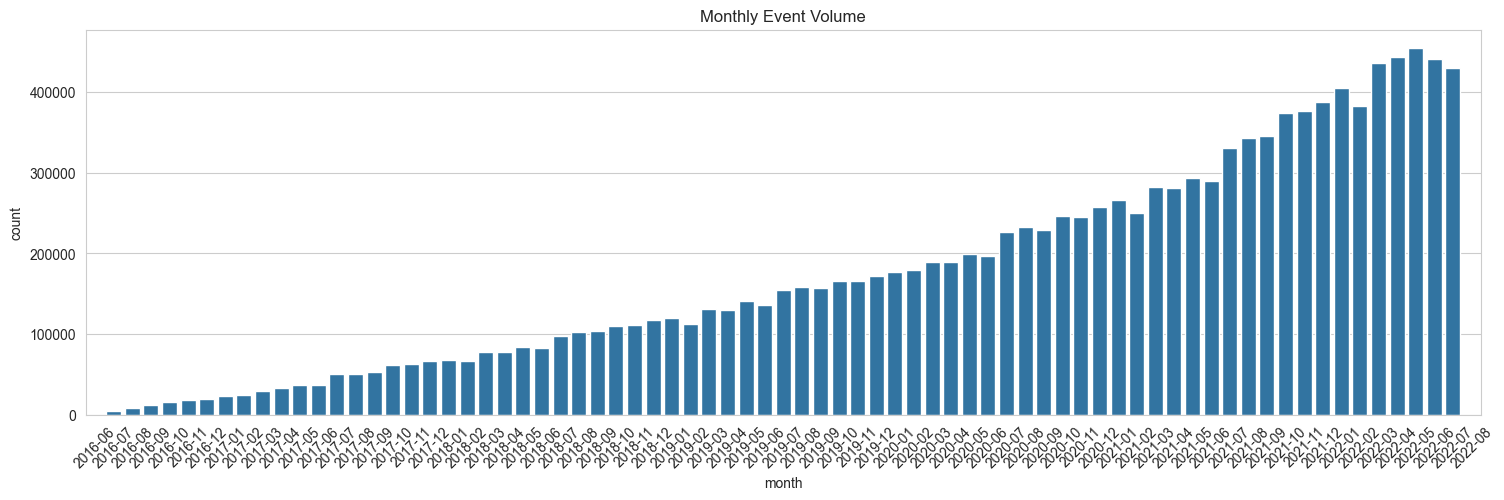

In [71]:
behavior_df["month"] = behavior_df["event_time"].dt.to_period("M")
monthly_events = behavior_df.groupby("month").size().reset_index(name="count")
monthly_events["month"] = monthly_events["month"].astype(str)
plt.figure(figsize=(18, 5))
sns.barplot(data=monthly_events, x="month", y="count")
plt.title("Monthly Event Volume")
plt.xticks(rotation=45)
plt.show()

C:\Users\hayao\AppData\Local\Temp\ipykernel_9572\2645049177.py:2: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  hourly_counts = behavior_df.groupby(['event_hour', 'traffic_source']).size().reset_index(name='event_count')


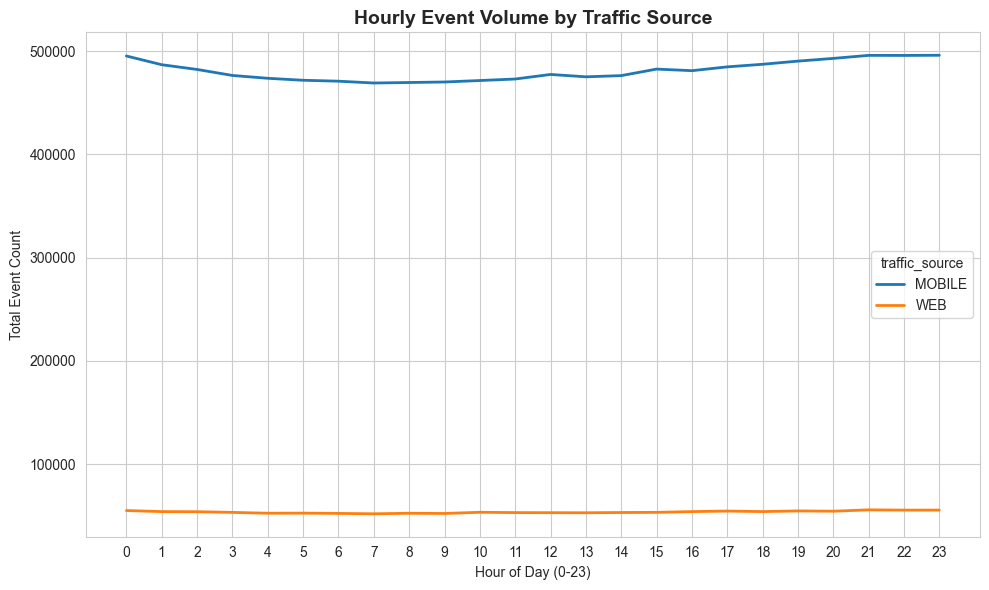

In [ ]:
plt.figure(figsize=(10, 6))
sns.lineplot(
    data=behavior_df,
    x="hour",
    y="event_id",
    hue="device_type",
    estimator="count",
    errorbar=None,
)
plt.title("Hourly Event Count by Device Type")
plt.ylabel("Event Count")
plt.show()

## Behavioral analysis

In [7]:
promo_usage = (
    behavior_df[behavior_df["promo_code"] != "NO_PROMO"]
    .groupby("session_id")
    .size()
    .reset_index(name="promo_events")
)
print(f"Sessions with at least one promo event: {promo_usage['session_id'].nunique()}")
print(f"Total sessions: {behavior_df['session_id'].nunique()}")

Sessions with at least one promo event: 326535
Total sessions: 895203


In [9]:
# Assume sales_df is loaded and has session_id and booking_id
booked_sessions = set(sales_df["session_id"].unique())
behavior_df["is_booked"] = behavior_df["session_id"].isin(booked_sessions)

cart_sessions = behavior_df[behavior_df["event_name"] == "ADD_TO_CART"][
    "session_id"
].unique()
abandoned = [s for s in cart_sessions if s not in booked_sessions]
print(f"Sessions with ADD_TO_CART: {len(cart_sessions)}")
print(f"Sessions with ADD_TO_CART but no booking: {len(abandoned)}")
print(f"Abandonment rate: {len(abandoned) / len(cart_sessions) * 100:.2f}%")

Sessions with ADD_TO_CART: 872061
Sessions with ADD_TO_CART but no booking: 19479
Abandonment rate: 2.23%


C:\Users\hayao\AppData\Local\Temp\ipykernel_9572\3951755223.py:2: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  rain_activity = behavior_df.groupby('rain_category')['event_id'].count().reset_index(name='events')


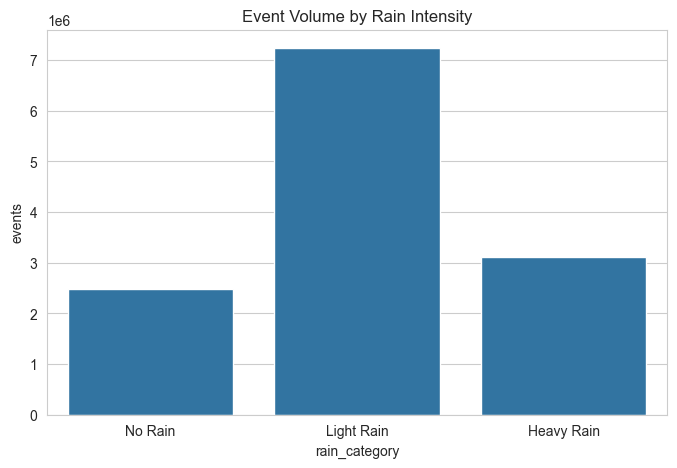

In [12]:
behavior_df["rain_category"] = pd.cut(
    behavior_df["precipitation"],
    bins=[-1, 0.1, 10, 100],
    labels=["No Rain", "Light Rain", "Heavy Rain"],
)
rain_activity = (
    behavior_df.groupby("rain_category")["event_id"].count().reset_index(name="events")
)
plt.figure(figsize=(8, 5))
sns.barplot(data=rain_activity, x="rain_category", y="events")
plt.title("Event Volume by Rain Intensity")
plt.show()

## Sessions analysis

In [11]:
# Compute session stats
session_stats = behavior_df.groupby("session_id").agg(
    first_time=("event_time", "min"),
    last_time=("event_time", "max"),
    event_count=("event_id", "count"),
)
session_stats["duration_sec"] = (
    session_stats["last_time"] - session_stats["first_time"]
).dt.total_seconds()
session_stats["duration_min"] = session_stats["duration_sec"] / 60

print(session_stats[["event_count", "duration_min"]].describe())

         event_count  duration_min
count  895203.000000  8.952030e+05
mean       14.335968  1.583906e+04
std        13.654071  3.857753e+04
min         2.000000  0.000000e+00
25%         6.000000  1.189425e+03
50%        10.000000  5.366300e+03
75%        18.000000  1.552022e+04
max       650.000000  1.360342e+06


In [13]:
first_events = (
    behavior_df.sort_values("event_time").groupby("session_id")["event_name"].first()
)
print(first_events.value_counts().head(10))

event_name
HOMEPAGE       894740
ADD_TO_CART       150
CLICK             121
SCROLL             61
SEARCH             51
ITEM_DETAIL        45
PROMO_PAGE         27
ADD_PROMO           8
BOOKING             0
Name: count, dtype: int64


In [14]:
# For sessions with at least two events, compute most common transitions
events_sorted = behavior_df.sort_values(["session_id", "event_time"])
events_sorted["next_event"] = events_sorted.groupby("session_id")["event_name"].shift(
    -1
)
transitions = (
    events_sorted.groupby(["event_name", "next_event"]).size().reset_index(name="count")
)
# Remove rows where next_event is NaN
transitions = transitions.dropna().sort_values("count", ascending=False)
print(transitions.head(10))

C:\Users\hayao\AppData\Local\Temp\ipykernel_9572\1609891070.py:4: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  transitions = events_sorted.groupby(['event_name', 'next_event']).size().reset_index(name='count')


     event_name   next_event   count
37     HOMEPAGE  ADD_TO_CART  615996
30        CLICK        CLICK  550899
39     HOMEPAGE        CLICK  425910
40     HOMEPAGE     HOMEPAGE  420488
10  ADD_TO_CART  ADD_TO_CART  405125
12  ADD_TO_CART        CLICK  394692
66       SCROLL        CLICK  366718
34        CLICK       SCROLL  365988
28        CLICK  ADD_TO_CART  315392
31        CLICK     HOMEPAGE  298645


In [16]:
item_views = (
    behavior_df[behavior_df["event_name"] == "ITEM_DETAIL"].groupby("session_id").size()
)
print("Item views per session (among those with at least one):")
print(item_views.describe())

Item views per session (among those with at least one):
count    520780.000000
mean          2.477814
std           2.347976
min           1.000000
25%           1.000000
50%           2.000000
75%           3.000000
max          74.000000
dtype: float64


C:\Users\hayao\AppData\Local\Temp\ipykernel_9572\2186974752.py:5: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  funnel = behavior_df.groupby('event_name')['session_id'].nunique().reset_index()


Funnel Summary:
         event  unique_sessions  conversion_from_prev  conversion_from_home
0     HOMEPAGE           895203                   NaN            100.000000
1       SEARCH           490846             54.830692             54.830692
2  ITEM_DETAIL           520780            106.098450             58.174515
3      BOOKING           852582            163.712508             95.238957


C:\Users\hayao\AppData\Local\Temp\ipykernel_9572\2186974752.py:20: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(data=funnel, x='event', y='unique_sessions', palette='Blues_d')


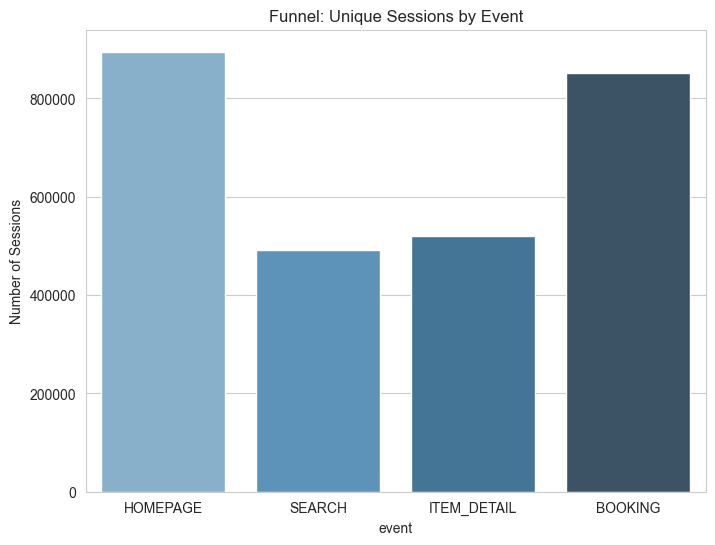

In [17]:
# Define event order
event_order = ["HOMEPAGE", "SEARCH", "ITEM_DETAIL", "BOOKING"]

# Count unique sessions that reached each event
funnel = behavior_df.groupby("event_name")["session_id"].nunique().reset_index()
funnel.columns = ["event", "unique_sessions"]
funnel = funnel[funnel["event"].isin(event_order)]
funnel = funnel.set_index("event").reindex(event_order).reset_index()
funnel.columns = ["event", "unique_sessions"]

# Compute conversion rates
funnel["conversion_from_prev"] = (
    funnel["unique_sessions"] / funnel["unique_sessions"].shift(1) * 100
)
funnel["conversion_from_home"] = (
    funnel["unique_sessions"] / funnel["unique_sessions"].iloc[0] * 100
)

print("Funnel Summary:")
print(funnel)

# Plot
plt.figure(figsize=(8, 6))
sns.barplot(data=funnel, x="event", y="unique_sessions", palette="Blues_d")
plt.title("Funnel: Unique Sessions by Event")
plt.ylabel("Number of Sessions")
plt.show()

In [19]:
# 1. Get unique session IDs for successful bookings
booked_sessions = sales_df["session_id"].unique()

# 2. Filter behavior_df for ITEM_DETAIL views
item_views = behavior_df[behavior_df["event_name"] == "ITEM_DETAIL"]

# 3. Find Abandoned Sessions
# ~isin() is the Pandas vectorized way to say "NOT IN", much faster than set() subtraction
abandoned_views = item_views[~item_views["session_id"].isin(booked_sessions)]

# 4. Calculate averages directly from your Gold tables!
# We use .groupby('session_id').first() so we don't count the rain 5 times
# if a user looked at 5 items in the same session.
avg_rain_abandoned = (
    abandoned_views.groupby("session_id")["precipitation"].first().mean()
)
avg_rain_booked = sales_df.groupby("session_id")["precipitation"].first().mean()

# Print results
print(f"Avg rain on abandoned sessions: {avg_rain_abandoned:.2f} mm")
print(f"Avg rain on booked sessions: {avg_rain_booked:.2f} mm")

Avg rain on abandoned sessions: 0.00 mm
Avg rain on booked sessions: 7.21 mm


In [20]:
top_brand_by_province = (
    sales_df.groupby(["home_location", "brand"])["total_amount"]
    .sum()
    .groupby(level=0)
    .idxmax()
    .reset_index()
)
top_brand_by_province.columns = ["home_location", "brand"]
print("Top brand by province:")
print(top_brand_by_province.head(10))

Top brand by province:
     home_location                    brand
0             Aceh             (Aceh, Nike)
1             Bali             (Bali, Nike)
2  Bangka Belitung  (Bangka Belitung, Puma)
3           Banten           (Banten, Nike)
4         Bengkulu         (Bengkulu, Puma)
5        Gorontalo        (Gorontalo, Puma)
6     Jakarta Raya     (Jakarta Raya, Puma)
7            Jambi            (Jambi, Puma)
8       Jawa Barat       (Jawa Barat, Nike)
9      Jawa Tengah      (Jawa Tengah, Nike)


C:\Users\hayao\AppData\Local\Temp\ipykernel_9572\3387739589.py:1: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  top_brand_by_province = sales_df.groupby(['home_location', 'brand'])['total_amount'].sum().groupby(level=0).idxmax().reset_index()


In [21]:
# Get booking time per session (from sales_df)
booking_time = (
    sales_df[["session_id", "created_at"]]
    .drop_duplicates()
    .rename(columns={"created_at": "booking_time"})
)

# Merge to get events before booking
behavior_df_booking = behavior_df.merge(booking_time, on="session_id", how="left")
pre_booking = behavior_df_booking[
    behavior_df_booking["event_time"] < behavior_df_booking["booking_time"]
]

# Count ITEM_DETAIL events per session
depth = (
    pre_booking[pre_booking["event_name"] == "ITEM_DETAIL"].groupby("session_id").size()
)
print("Session depth (number of item_detail views before booking):")
print(depth.describe())

Session depth (number of item_detail views before booking):
count    478097.000000
mean          2.283541
std           1.960463
min           1.000000
25%           1.000000
50%           2.000000
75%           3.000000
max          36.000000
dtype: float64
